# Лабораторная работа №2. Классификация и нейронные сети

## Вариант: **Titanic Survival** — предсказание выживаемости пассажиров «Титаника»

**Цель работы:** изучить методы классификации библиотеки Scikit-Learn, построить и сравнить классификаторы, освоить построение нейронных сетей на TensorFlow/Keras и визуализацию процесса обучения с помощью TensorBoard.

**Задачи работы:**

1. Выбрать и подготовить датасет для бинарной классификации.
2. Выполнить разведочный анализ, обработать пропуски, закодировать категориальные признаки, масштабировать числовые.
3. Разбить выборку на обучающую и тестовую (стратифицированно).
4. Построить классификаторы пяти групп методов:
   - наивный байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
   - дерево решений (Decision Tree);
   - линейный дискриминантный анализ (LDA);
   - метод опорных векторов (SVM);
   - метод k ближайших соседей (kNN).
5. Оценить модели метриками Accuracy, Precision, Recall, F1-score, AUC-ROC; построить ROC-кривые и матрицы ошибок.
6. Настроить гиперпараметры каждого метода и исследовать влияние параметров на качество.
7. Реализовать нейронную сеть на TensorFlow, провести эксперименты с гиперпараметрами и залогировать обучение в TensorBoard.
8. Сравнить все подходы и аргументировать выбор лучшей модели для данной задачи.

**Данные:** открытый датасет Kaggle «Titanic: Machine Learning from Disaster» (файл `titanic.csv`, 891 пассажир, 12 столбцов). Целевая переменная — `Survived` (1 — выжил, 0 — погиб).

> Все эксперименты воспроизводимы: фиксируется `RANDOM_STATE = 42` для NumPy, TensorFlow и разбиения данных.

## 1. Импорт библиотек и настройка окружения

Используются: **Pandas/NumPy** (обработка данных), **Scikit-Learn** (классификаторы, препроцессинг, метрики, подбор гиперпараметров), **TensorFlow/Keras** (нейронная сеть), **Matplotlib/Seaborn** (визуализация), **TensorBoard** (мониторинг обучения).

Для воспроизводимости фиксируются seed'ы. Все рисунки сохраняются в каталог `figures_titanic/`, логи TensorBoard — в `logs_tb_titanic/`.

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("figures_titanic")
FIG_DIR.mkdir(exist_ok=True)
LOG_DIR = Path("logs_tb_titanic")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", "да" if tf.config.list_physical_devices("GPU") else "нет (CPU)")

NumPy: 2.5.4
Pandas: 3.1.1
TensorFlow: 2.21.0


GPU: нет (CPU)


## 2. Выбор и подготовка датасета

### 2.1. Общая характеристика

**Titanic Survival** — классическая задача бинарной классификации: по сведениям о пассажире (класс билета, пол, возраст, состав семьи, стоимость билета, порт посадки и т.д.) нужно предсказать, выжил он или нет.

| Свойство | Значение |
|:---|:---|
| Число наблюдений | 891 |
| Число исходных признаков | 11 + целевая переменная |
| Целевая переменная | `Survived` ∈ {0, 1} |
| Доля выживших | ≈ 38.4 % |
| Пропуски | `Age` ≈ 19.9 %, `Cabin` ≈ 77.1 %, `Embarked` ≈ 0.2 % |

Такой датасет удобен для лабораторной работы: он компактный (быстро обучаются SVM, kNN, GridSearchCV), содержит и числовые, и категориальные признаки, а также пропуски — то есть требует полноценной предобработки. Дисбаланс классов умеренный (≈ 62 / 38), поэтому наряду с Accuracy информативны F1 и AUC-ROC.

### 2.2. Описание признаков

| Признак | Тип | Описание | Обработка |
|:---|:---|:---|:---|
| `PassengerId` | int | идентификатор | удаляется |
| `Pclass` | порядковый | класс билета (1/2/3) | числовой, стандартизация |
| `Name` | текст | имя пассажира | извлекается `Title` (Mr/Mrs/Miss/Master/Officer/Noble/Rare), затем удаляется |
| `Sex` | категориальный | пол | one-hot |
| `Age` | числовой | возраст, есть пропуски | медианная импутация + `AgeKnown`, стандартизация |
| `SibSp` | int | братья/сёстры/супруги на борту | числовой |
| `Parch` | int | родители/дети на борту | числовой |
| `Ticket` | текст | номер билета | удаляется (высокая кардинальность) |
| `Fare` | числовой | стоимость билета | `log1p(Fare)` — сглаживание сильной асимметрии |
| `Cabin` | текст | каюта | `Deck` (первая буква) + `HasCabin` |
| `Embarked` | категориальный | порт посадки | пропуски → мода, one-hot |
| `FamilySize` | производный | `SibSp + Parch + 1` | числовой |
| `IsAlone` | производный | `FamilySize == 1` | бинарный |
| **`Survived`** | **цель** | **выжил (1/0)** | — |

### 2.3. Загрузка данных

Файл `titanic.csv` лежит рядом с ноутбуком. Если файла нет, он автоматически скачивается из открытого репозитория (datasciencedojo/datasets) — так ноутбук остаётся воспроизводимым.

In [2]:
DATA_PATH = Path("titanic.csv")
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Данные загружены из {DATA_PATH.resolve()}")
else:
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)
    print("Файл отсутствовал — данные скачаны и сохранены в titanic.csv")

print("Размер датасета:", df.shape)
df.head()

Данные загружены из D:\NGTU\4_Kyrs\6_semestr\II_interface\laba_2\titanic.csv
Размер датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Сводная информация о типах и пропусках
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
summary

,dtype,non_null,missing,missing_pct,unique
PassengerId,int64,891,0,0.00,891
Survived,int64,891,0,0.00,2
Pclass,int64,891,0,0.00,3
Name,str,891,0,0.00,891
Sex,str,891,0,0.00,2
Age,float64,714,177,19.87,88
SibSp,int64,891,0,0.00,7
Parch,int64,891,0,0.00,7
Ticket,str,891,0,0.00,681
Fare,float64,891,0,0.00,248


### 2.4. Разведочный анализ данных (EDA)

Посмотрим на баланс классов, зависимость выживаемости от пола и класса, распределение возраста и стоимости билета. Эти графики важны: они показывают, какие признаки заведомо информативны (пол и класс билета — сильнейшие предикторы).

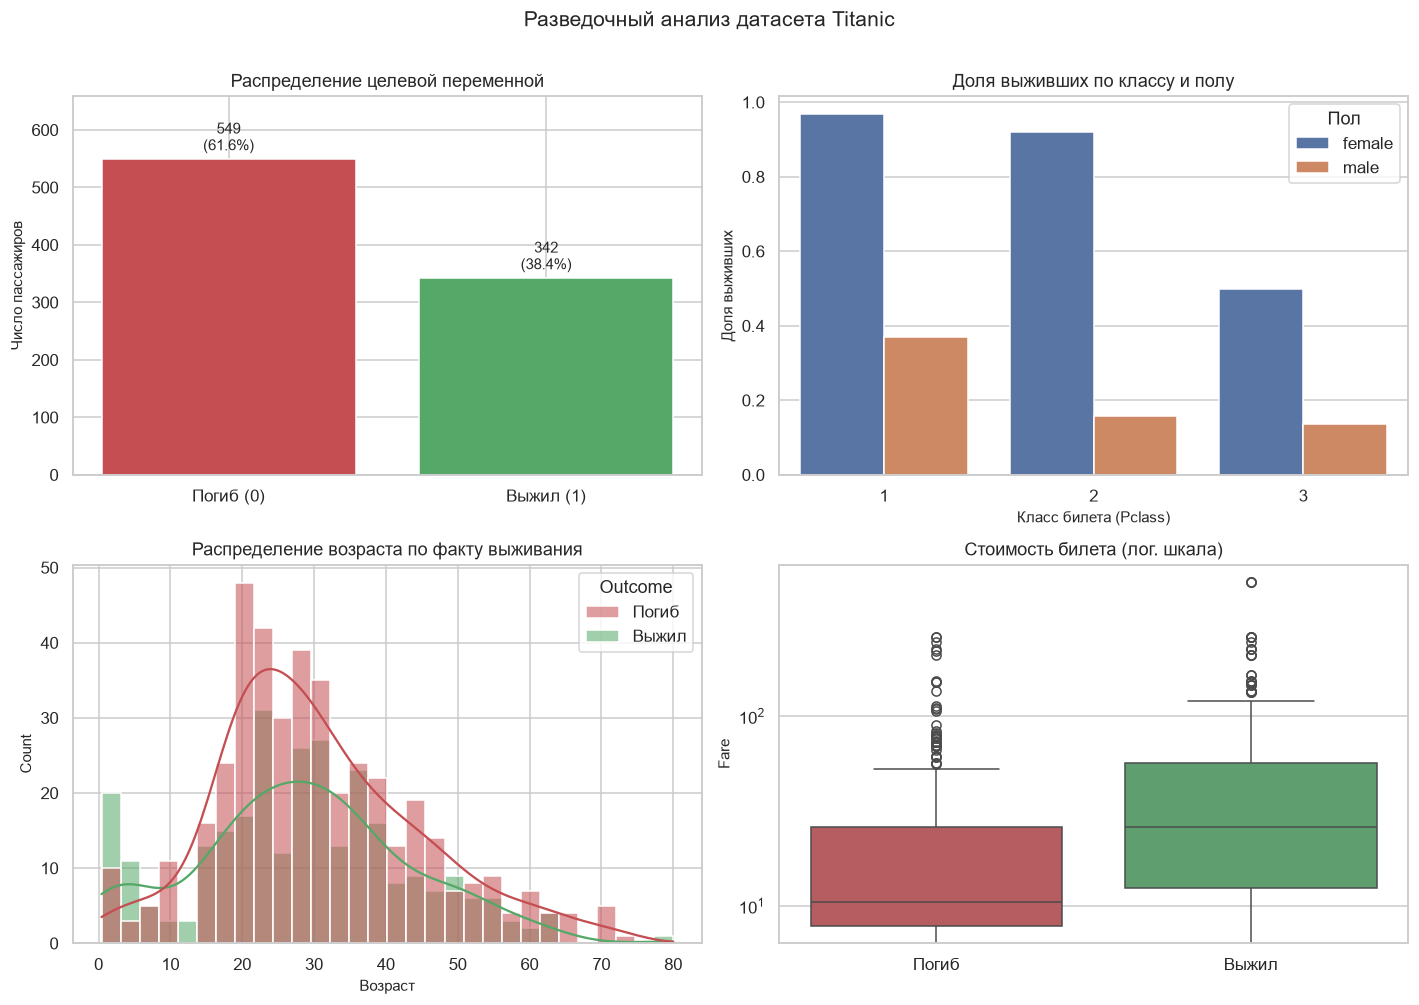

In [4]:
df_plot = df.assign(Outcome=df["Survived"].map({0: "Погиб", 1: "Выжил"}))
palette = {"Погиб": "#c44e52", "Выжил": "#55a868"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Баланс классов
ax = axes[0, 0]
counts = df["Survived"].value_counts().sort_index()
bars = ax.bar(["Погиб (0)", "Выжил (1)"], counts.values, color=["#c44e52", "#55a868"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v}\n({v / len(df):.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Распределение целевой переменной")
ax.set_ylabel("Число пассажиров")
ax.set_ylim(0, counts.max() * 1.2)

# 2. Выживаемость по полу и классу
ax = axes[0, 1]
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", ax=ax, errorbar=None)
ax.set_title("Доля выживших по классу и полу")
ax.set_xlabel("Класс билета (Pclass)")
ax.set_ylabel("Доля выживших")
ax.legend(title="Пол")

# 3. Возраст
ax = axes[1, 0]
sns.histplot(data=df_plot, x="Age", hue="Outcome", bins=30, kde=True,
             palette=palette, ax=ax, alpha=0.55)
ax.set_title("Распределение возраста по факту выживания")
ax.set_xlabel("Возраст")

# 4. Стоимость билета
ax = axes[1, 1]
sns.boxplot(data=df_plot, x="Outcome", y="Fare", hue="Outcome",
            palette=palette, legend=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Стоимость билета (лог. шкала)")
ax.set_xlabel("")
ax.set_ylabel("Fare")

fig.suptitle("Разведочный анализ датасета Titanic", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda.png", bbox_inches="tight")
plt.show()

**Выводы из EDA:**

- Женщины выживали значительно чаще мужчин, а пассажиры 1-го класса — чаще пассажиров 3-го. Пол и класс билета — ключевые признаки.
- Дети также имели повышенные шансы на выживание.
- Распределение `Fare` сильно асимметрично (есть очень дорогие билеты), поэтому используется логарифмирование.
- Пропуски в `Age` и `Cabin` нужно обрабатывать внутри пайплайна, чтобы избежать утечки информации из тестовой выборки.

### 2.5. Конструирование признаков

Помимо базовых столбцов добавляются производные:

- `Title` — обращение из имени (`Mr`, `Mrs`, `Miss`, `Master`, а также `Officer`, `Noble`, `Rare`). Признак косвенно кодирует пол, возраст и социальный статус.
- `FamilySize = SibSp + Parch + 1` и `IsAlone` — размер семьи и признак одиночного путешествия.
- `Deck` — палуба (первая буква номера каюты), `HasCabin` — известна ли каюта. Пропуск каюты сам по себе информативен (обычно это пассажиры 3-го класса).
- `FareLog = log1p(Fare)` — уменьшает асимметрию.
- `AgeKnown` — факт наличия возраста (пропуски чаще у пассажиров 3-го класса).

Числовые признаки масштабируются `StandardScaler`, категориальные кодируются `OneHotEncoder`. Пропуски заполняются внутри `Pipeline`/`ColumnTransformer`: медианой для чисел и модой для категорий. Благодаря этому при кросс-валидации параметры импутации и масштабирования оцениваются только на обучающих фолдах — утечки нет.

Для MultinomialNB, ComplementNB и BernoulliNB нужны неотрицательные признаки, поэтому для них используется отдельный препроцессор с `MinMaxScaler`.

In [5]:
TITLE_MAP = {
    "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
    "Dr": "Officer", "Rev": "Officer", "Col": "Officer", "Major": "Officer",
    "Capt": "Officer", "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Noble", "Countess": "Noble", "Sir": "Noble",
    "Jonkheer": "Noble", "Don": "Noble", "Dona": "Noble",
}

def prepare_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d["Title"] = (d["Name"].str.extract(r",\s*([^\.]+)\.")[0]
                  .str.strip().map(TITLE_MAP).fillna("Rare"))
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    d["Deck"] = d["Cabin"].str[0].fillna("U")
    d["FareLog"] = np.log1p(d["Fare"])
    d["AgeKnown"] = d["Age"].notna().astype(int)
    return d

df_prep = prepare_features(df)

NUM_COLS = ["Pclass", "Age", "SibSp", "Parch", "FareLog",
            "FamilySize", "IsAlone", "HasCabin", "AgeKnown"]
CAT_COLS = ["Sex", "Embarked", "Title", "Deck"]

print("Признаков всего:", len(NUM_COLS) + len(CAT_COLS))
print("Числовые:      ", NUM_COLS)
print("Категориальные:", CAT_COLS)
print("\nРаспределение Title:")
print(df_prep["Title"].value_counts())
print("\nРаспределение Deck:")
print(df_prep["Deck"].value_counts())

Признаков всего: 13
Числовые:       ['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog', 'FamilySize', 'IsAlone', 'HasCabin', 'AgeKnown']
Категориальные: ['Sex', 'Embarked', 'Title', 'Deck']

Распределение Title:
Title
Mr         517
Miss       185
Mrs        126
Master      40
Officer     18
Noble        4
Rare         1
Name: count, dtype: int64

Распределение Deck:
Deck
U    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64


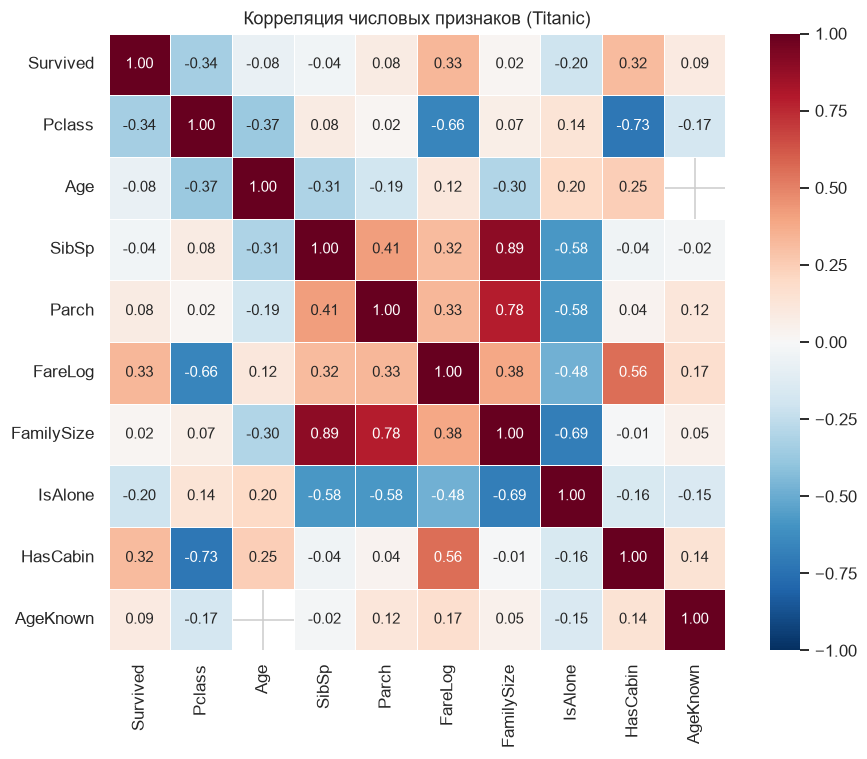

In [6]:
# Корреляционная матрица числовых признаков и цели
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "FareLog",
             "FamilySize", "IsAlone", "HasCabin", "AgeKnown"]
corr = df_prep[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Корреляция числовых признаков (Titanic)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_correlation.png", bbox_inches="tight")
plt.show()

### 2.6. Формирование матрицы признаков и целевого вектора

In [7]:
X = df_prep[NUM_COLS + CAT_COLS].copy()
y = df_prep["Survived"].astype(int)

print("X:", X.shape)
print("y:", y.shape, "| доля выживших:", round(y.mean(), 4))
print("Соотношение классов:", dict(y.value_counts().sort_index()))

X: (891, 13)
y: (891,) | доля выживших: 0.3838
Соотношение классов: {0: np.int64(549), 1: np.int64(342)}


In [8]:
# Числовые признаки: импутация медианой + стандартизация (или MinMax для NB)
num_pipe_std = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
num_pipe_mm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe_std, NUM_COLS),
    ("cat", cat_pipe, CAT_COLS),
])
preprocessor_mm = ColumnTransformer([
    ("num", num_pipe_mm, NUM_COLS),
    ("cat", cat_pipe, CAT_COLS),
])

# Проверка размерности после кодирования
X_check = preprocessor.fit_transform(X)
print("Размерность после ColumnTransformer:", X_check.shape)
print("Пример названий признаков:", list(preprocessor.get_feature_names_out())[:12], "...")

Размерность после ColumnTransformer: (891, 30)
Пример названий признаков: ['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__FareLog', 'num__FamilySize', 'num__IsAlone', 'num__HasCabin', 'num__AgeKnown', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C'] ...


## 3. Разбиение выборки

Данные делятся на обучающую (80 %) и тестовую (20 %) части со **стратификацией по `Survived`**, чтобы соотношение классов сохранилось. Тестовая часть используется только для финальной оценки; все подборы гиперпараметров выполняются по кросс-валидации на обучающей части.

Параметры: `test_size=0.2`, `random_state=42`, `stratify=y`.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

split_info = pd.DataFrame({
    "Выборка": ["Train", "Test"],
    "Объектов": [len(y_train), len(y_test)],
    "Доля выживших": [round(y_train.mean(), 4), round(y_test.mean(), 4)],
})
print(split_info.to_string(index=False))
print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)

Выборка  Объектов  Доля выживших
  Train       712         0.3834
   Test       179         0.3855

X_train: (712, 13) | X_test: (179, 13)


### 3.1. Метрики качества

| Метрика | Формула / смысл |
|:---|:---|
| **Accuracy** | $\dfrac{TP+TN}{TP+TN+FP+FN}$ — доля верных ответов |
| **Precision** | $\dfrac{TP}{TP+FP}$ — точность положительных предсказаний |
| **Recall** | $\dfrac{TP}{TP+FN}$ — полнота (доля найденных выживших) |
| **F1-score** | $2\cdot\dfrac{Precision\cdot Recall}{Precision+Recall}$ — гармоническое среднее |
| **AUC-ROC** | площадь под ROC-кривой; вероятность, что случайный выживший получил больший скор, чем случайный погибший |

Положительный класс — `Survived = 1` (выжил). Accuracy на несбалансированных классах может быть обманчиво высокой, поэтому основное внимание — F1 и AUC-ROC.

## 4. Методы классификации

### 4.1. Краткое описание методов

| Метод | Идея | Особенности применения к Titanic |
|:---|:---|:---|
| **GaussianNB** | признаки внутри класса распределены нормально, условно независимы | быстрый baseline; хорошо работает с масштабированными числовыми признаками |
| **MultinomialNB** | модель частот/счётчиков, неотрицательные признаки | после `MinMaxScaler` — эвристика, но часто даёт неплохой результат |
| **ComplementNB** | вариант NB, устойчивый к дисбалансу классов | дополняет MultinomialNB, полезен при перекосе классов |
| **BernoulliNB** | бинаризованные признаки, модель Бернулли | хорошо сочетается с one-hot кодированием |
| **Decision Tree** | рекурсивное разбиение пространства признаков по порогам | интерпретируемость; склонно к переобучению, нужен контроль глубины |
| **LDA** | линейные дискриминантные функции, гауссовские классы с общей ковариацией | строит линейную границу; полезна регуляризация (shrinkage) |
| **SVM (RBF)** | максимизация зазора, нелинейное ядро | сильный кандидат для табличных данных; важны `C` и `gamma` |
| **kNN** | голосование $k$ ближайших соседей | чувствителен к масштабу и выбору $k$; после стандартизации работает хорошо |

### 4.2. Базовые модели (без подбора гиперпараметров)

Сначала обучаются модели с «разумными по умолчанию» параметрами. Это точка отсчёта, с которой сравнивается эффект подбора гиперпараметров.

- NB-модели используют `preprocessor_mm` (MinMax, неотрицательные признаки).
- Остальные модели — `preprocessor` (StandardScaler).
- Для SVM включён `probability=True`, чтобы получить вероятности для AUC-ROC.

In [10]:
results = []
probas = {}
fitted = {}

def evaluate_model(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
    }
    results.append(row)
    probas[name] = proba
    fitted[name] = model
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Погиб (0)", "Выжил (1)"],
                                digits=3, zero_division=0))
    return model

In [11]:
baseline_models = {
    "GaussianNB": Pipeline([("prep", preprocessor), ("clf", GaussianNB())]),
    "MultinomialNB": Pipeline([("prep", preprocessor_mm), ("clf", MultinomialNB(alpha=1.0))]),
    "ComplementNB": Pipeline([("prep", preprocessor_mm), ("clf", ComplementNB(alpha=1.0))]),
    "BernoulliNB": Pipeline([("prep", preprocessor_mm),
                             ("clf", BernoulliNB(alpha=1.0, binarize=0.5))]),
    "DecisionTree": Pipeline([("prep", preprocessor),
                              ("clf", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]),
    "LDA": Pipeline([("prep", preprocessor), ("clf", LinearDiscriminantAnalysis())]),
    "SVM": Pipeline([("prep", preprocessor),
                     ("clf", SVC(kernel="rbf", C=1.0, gamma="scale",
                                 probability=True, random_state=RANDOM_STATE))]),
    "kNN": Pipeline([("prep", preprocessor),
                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
}

for name, model in baseline_models.items():
    evaluate_model(name, model)

baseline_df = pd.DataFrame(results).set_index("Model").round(4)
baseline_df.sort_values("F1", ascending=False)


=== GaussianNB ===
              precision    recall  f1-score   support

   Погиб (0)      0.886     0.709     0.788       110
   Выжил (1)      0.648     0.855     0.738        69

    accuracy                          0.765       179
   macro avg      0.767     0.782     0.763       179
weighted avg      0.795     0.765     0.768       179


=== MultinomialNB ===
              precision    recall  f1-score   support

   Погиб (0)      0.817     0.773     0.794       110
   Выжил (1)      0.667     0.725     0.694        69

    accuracy                          0.754       179
   macro avg      0.742     0.749     0.744       179
weighted avg      0.759     0.754     0.756       179




=== ComplementNB ===
              precision    recall  f1-score   support

   Погиб (0)      0.825     0.727     0.773       110
   Выжил (1)      0.634     0.754     0.689        69

    accuracy                          0.737       179
   macro avg      0.729     0.740     0.731       179
weighted avg      0.751     0.737     0.740       179


=== BernoulliNB ===


              precision    recall  f1-score   support

   Погиб (0)      0.827     0.736     0.779       110
   Выжил (1)      0.642     0.754     0.693        69

    accuracy                          0.743       179
   macro avg      0.734     0.745     0.736       179
weighted avg      0.755     0.743     0.746       179


=== DecisionTree ===
              precision    recall  f1-score   support

   Погиб (0)      0.775     0.909     0.837       110
   Выжил (1)      0.800     0.580     0.672        69

    accuracy                          0.782       179
   macro avg      0.788     0.744     0.755       179
weighted avg      0.785     0.782     0.773       179




=== LDA ===


              precision    recall  f1-score   support

   Погиб (0)      0.861     0.900     0.880       110
   Выжил (1)      0.828     0.768     0.797        69

    accuracy                          0.849       179
   macro avg      0.844     0.834     0.838       179
weighted avg      0.848     0.849     0.848       179




=== SVM ===
              precision    recall  f1-score   support

   Погиб (0)      0.840     0.909     0.873       110
   Выжил (1)      0.833     0.725     0.775        69

    accuracy                          0.838       179
   macro avg      0.837     0.817     0.824       179
weighted avg      0.838     0.838     0.836       179




=== kNN ===
              precision    recall  f1-score   support

   Погиб (0)      0.825     0.855     0.839       110
   Выжил (1)      0.754     0.710     0.731        69

    accuracy                          0.799       179
   macro avg      0.789     0.782     0.785       179
weighted avg      0.797     0.799     0.798       179



,Accuracy,Precision,Recall,F1,AUC-ROC
Model,,,,,
LDA,0.8492,0.8281,0.7681,0.7970,0.8623
SVM,0.8380,0.8333,0.7246,0.7752,0.8528
GaussianNB,0.7654,0.6484,0.8551,0.7375,0.7742
kNN,0.7989,0.7538,0.7101,0.7313,0.8254
MultinomialNB,0.7542,0.6667,0.7246,0.6944,0.8167
BernoulliNB,0.7430,0.6420,0.7536,0.6933,0.8330
ComplementNB,0.7374,0.6341,0.7536,0.6887,0.8167
DecisionTree,0.7821,0.8000,0.5797,0.6723,0.8301


### 4.3. ROC-кривые и сравнение метрик базовых моделей

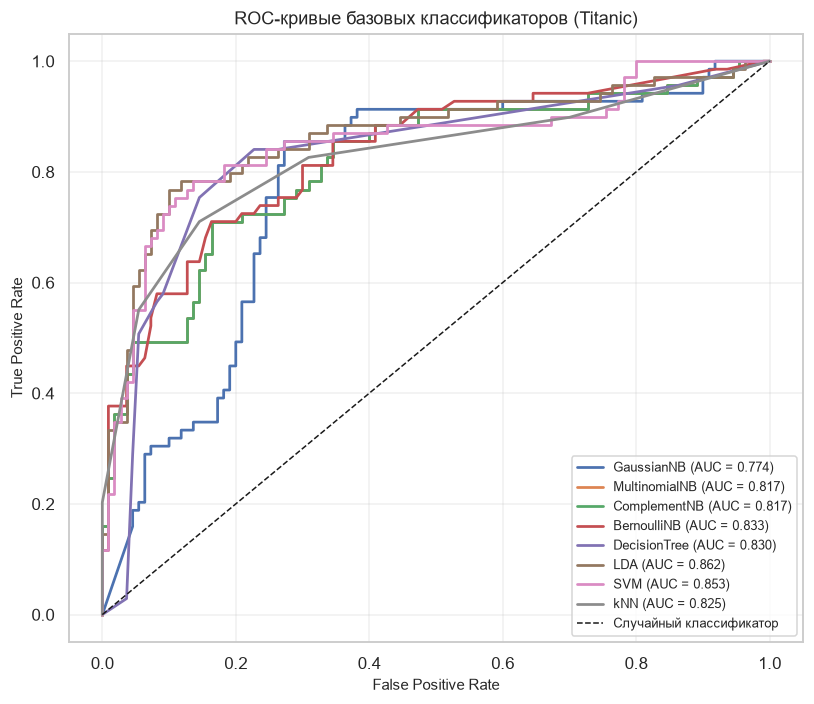

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Случайный классификатор")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривые базовых классификаторов (Titanic)")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_roc_baseline.png", bbox_inches="tight")
plt.show()

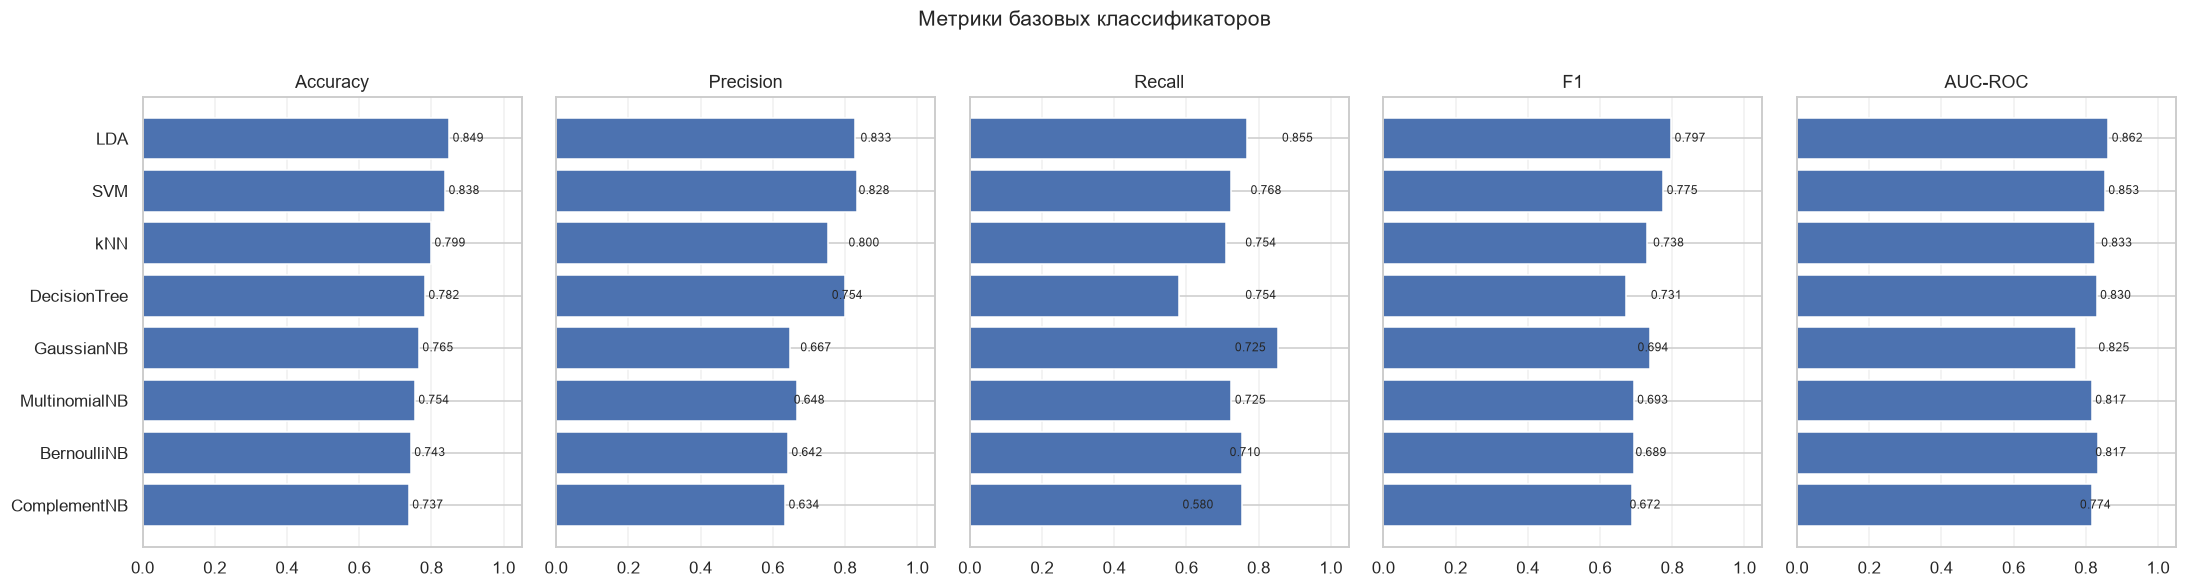

In [13]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
fig, axes = plt.subplots(1, 5, figsize=(20, 5.2), sharey=True)

for ax, metric in zip(axes, metrics):
    order = baseline_df.sort_values(metric)
    ax.barh(order.index, order[metric], color="#4c72b0")
    ax.set_xlim(0, 1.05)
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(order[metric]):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)

fig.suptitle("Метрики базовых классификаторов", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_metrics_baseline.png", bbox_inches="tight")
plt.show()

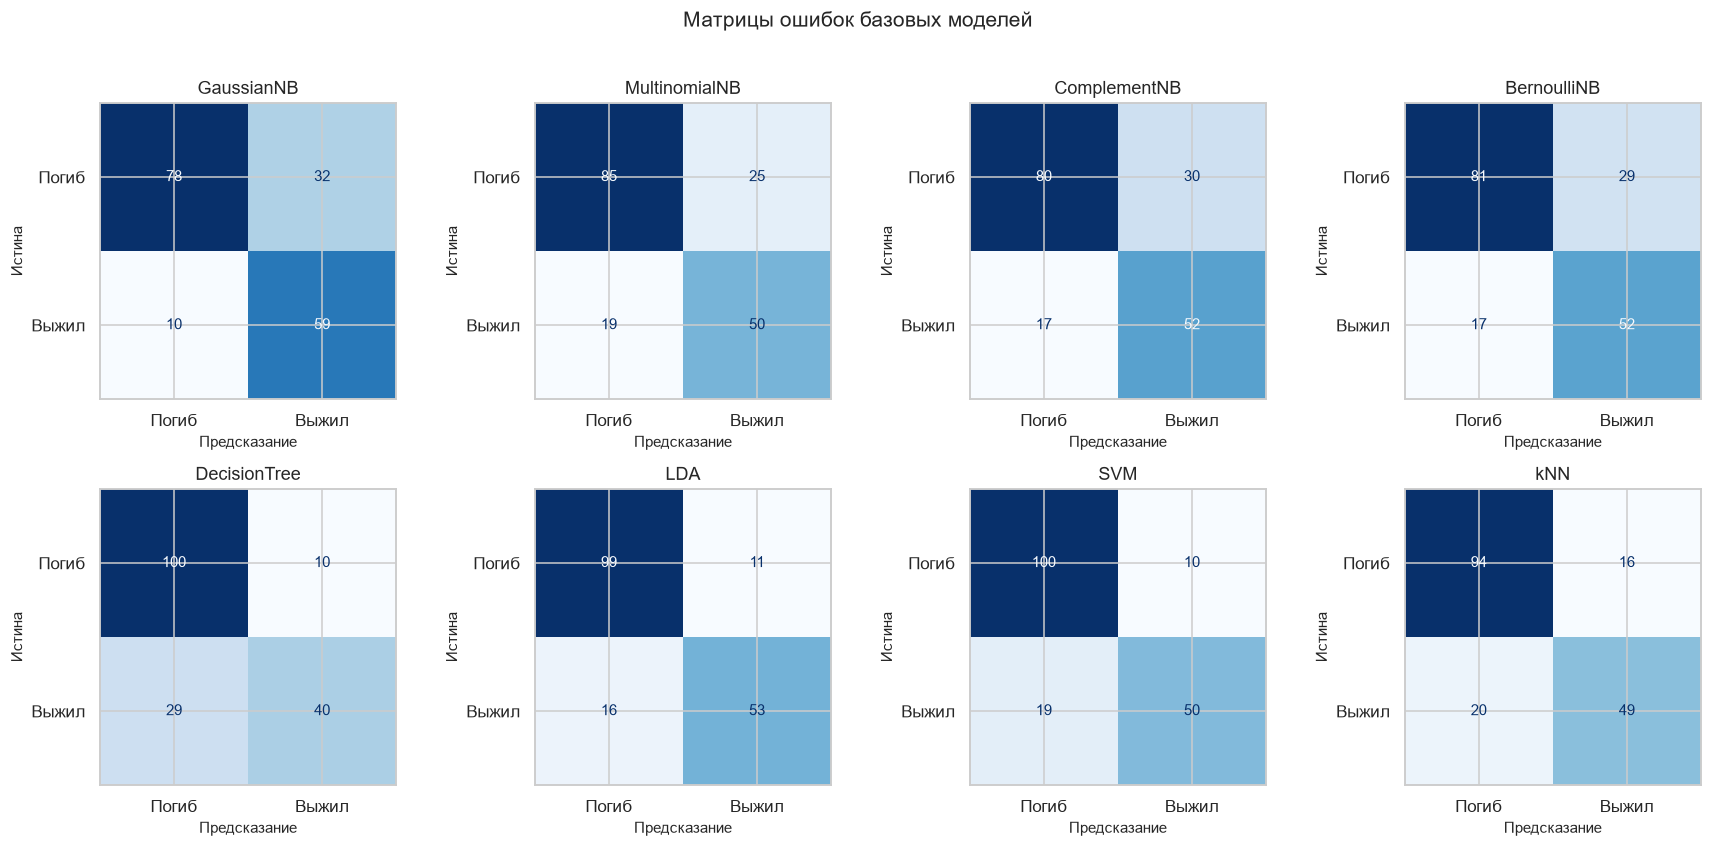

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, (name, model) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), display_labels=["Погиб", "Выжил"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истина")

fig.suptitle("Матрицы ошибок базовых моделей", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_confusion_baseline.png", bbox_inches="tight")
plt.show()

### 4.4. Анализ базовых результатов

- Все модели превзошли тривиальный baseline (≈ 61.6 % при постоянном предсказании «погиб»). Accuracy варьируется от **0.737** (ComplementNB) до **0.849** (LDA), AUC-ROC — от **0.774** (GaussianNB) до **0.862** (LDA).
- **Лучший baseline — LDA:** Accuracy 0.849, Precision 0.828, Recall 0.768, F1 0.797, AUC 0.862. После one-hot кодирования и стандартизации классы становятся почти линейно разделимыми, поэтому линейный дискриминант работает очень хорошо.
- **SVM (RBF)** почти не уступает: Accuracy 0.838, Precision 0.833, F1 0.775, AUC 0.853.
- **GaussianNB** даёт максимальный Recall (0.855) при Precision 0.648: модель часто предсказывает «выжил» и находит большинство выживших, но платит большим числом ложных срабатываний. При этом его AUC (0.774) — самый низкий: ранжирование вероятностей хуже, чем у остальных моделей.
- **MultinomialNB/ComplementNB/BernoulliNB** после MinMax-масштабирования работают скромнее по F1 (0.689–0.694), но BernoulliNB показывает AUC 0.833 — бинаризация one-hot признаков оказывается полезной для ранжирования.
- **Decision Tree** с `max_depth=5` смещён в сторону Precision (0.800) и имеет низкий Recall (0.580): дерево осторожно предсказывает «выжил» и пропускает часть выживших.
- **kNN (k = 5)** даёт Accuracy 0.799 и F1 0.731; без подбора k он чувствителен к шуму.

Точные значения метрик — в таблице выше. Далее гиперпараметры подбираются по **5-кратной стратифицированной кросс-валидации** на обучающей выборке; тест остаётся нетронутым.

## 5. Настройка гиперпараметров

Для каждого метода выполняется `GridSearchCV` с `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Критерий выбора — **F1-score** (компромисс Precision/Recall при умеренном дисбалансе). После подбора лучшая модель оценивается на тестовой выборке.

| Модель | Сетка гиперпараметров |
|:---|:---|
| **GaussianNB** | `var_smoothing` ∈ {1e-11 … 1e-5} |
| **MultinomialNB** | `alpha` ∈ {0.01, 0.03, 0.1, 0.3, 0.5, 1, 2, 5} |
| **ComplementNB** | `alpha` ∈ {0.01 … 5}, `norm` ∈ {False, True} |
| **BernoulliNB** | `alpha` ∈ {0.01, 0.1, 0.3, 0.5, 1, 2}, `binarize` ∈ {0, 0.25, 0.5, 0.75} |
| **DecisionTree** | `criterion` ∈ {gini, entropy}, `max_depth` ∈ {2…12, None}, `min_samples_leaf` ∈ {1, 2, 4, 8, 16} |
| **LDA** | `solver` ∈ {svd, lsqr, eigen}; для lsqr/eigen — `shrinkage` ∈ {None, auto, 0.1 … 0.9} |
| **SVM** | ядро rbf/linear/poly; `C` ∈ {0.1, 0.3, 1, 3, 10}; `gamma` ∈ {scale, 0.01, 0.03, 0.1, 0.3} |
| **kNN** | `n_neighbors` ∈ {3…31}, `weights` ∈ {uniform, distance}, `metric` ∈ {euclidean, manhattan} |

In [15]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_rows = []
tuned_models = {}
tuned_probas = {}

def tune_model(name, pipe, param_grid):
    gs = GridSearchCV(pipe, param_grid, cv=cv5, scoring="f1", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)

    pred = gs.predict(X_test)
    proba = gs.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Best_params": str(gs.best_params_),
        "CV_F1": gs.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
    }
    tuned_rows.append(row)
    tuned_models[name] = gs.best_estimator_
    tuned_probas[name] = proba
    print(f"{name:16s} | CV F1 = {gs.best_score_:.4f} | Test F1 = {row['F1']:.4f} | "
          f"Test AUC = {row['AUC-ROC']:.4f}")
    print(f"  лучшие параметры: {gs.best_params_}")
    return gs

In [16]:
tune_model("GaussianNB",
           Pipeline([("prep", preprocessor), ("clf", GaussianNB())]),
           {"clf__var_smoothing": np.logspace(-11, -5, 7)})

tune_model("MultinomialNB",
           Pipeline([("prep", preprocessor_mm), ("clf", MultinomialNB())]),
           {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0]})

tune_model("ComplementNB",
           Pipeline([("prep", preprocessor_mm), ("clf", ComplementNB())]),
           {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0],
            "clf__norm": [False, True]})

tune_model("BernoulliNB",
           Pipeline([("prep", preprocessor_mm), ("clf", BernoulliNB())]),
           {"clf__alpha": [0.01, 0.1, 0.3, 0.5, 1.0, 2.0],
            "clf__binarize": [0.0, 0.25, 0.5, 0.75]})

GaussianNB       | CV F1 = 0.7569 | Test F1 = 0.7468 | Test AUC = 0.7736
  лучшие параметры: {'clf__var_smoothing': np.float64(1e-05)}


MultinomialNB    | CV F1 = 0.7408 | Test F1 = 0.7000 | Test AUC = 0.8174
  лучшие параметры: {'clf__alpha': 5.0}


ComplementNB     | CV F1 = 0.7434 | Test F1 = 0.6846 | Test AUC = 0.8174
  лучшие параметры: {'clf__alpha': 5.0, 'clf__norm': False}


BernoulliNB      | CV F1 = 0.7460 | Test F1 = 0.6939 | Test AUC = 0.8341
  лучшие параметры: {'clf__alpha': 0.1, 'clf__binarize': 0.75}


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...rnoulliNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__alpha': [0.01, 0.1, ...], 'clf__binarize': [0.0, 0.25, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

In [17]:
tune_model("DecisionTree",
           Pipeline([("prep", preprocessor),
                     ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
           {"clf__criterion": ["gini", "entropy"],
            "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, 12, None],
            "clf__min_samples_leaf": [1, 2, 4, 8, 16],
            "clf__class_weight": [None, "balanced"]})

tune_model("LDA",
           Pipeline([("prep", preprocessor), ("clf", LinearDiscriminantAnalysis())]),
           [{"clf__solver": ["svd"]},
            {"clf__solver": ["lsqr", "eigen"],
             "clf__shrinkage": [None, "auto", 0.1, 0.3, 0.5, 0.7, 0.9]}])

tune_model("SVM",
           Pipeline([("prep", preprocessor),
                     ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
           [{"clf__kernel": ["rbf"],
             "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0],
             "clf__gamma": ["scale", 0.01, 0.03, 0.1, 0.3]},
            {"clf__kernel": ["linear"],
             "clf__C": [0.1, 0.3, 1.0, 3.0, 10.0]},
            {"clf__kernel": ["poly"],
             "clf__degree": [2, 3],
             "clf__C": [0.1, 1.0, 10.0],
             "clf__gamma": ["scale", 0.03, 0.1]}])

tune_model("kNN",
           Pipeline([("prep", preprocessor), ("clf", KNeighborsClassifier())]),
           {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25, 31],
            "clf__weights": ["uniform", "distance"],
            "clf__metric": ["euclidean", "manhattan"]})

DecisionTree     | CV F1 = 0.7673 | Test F1 = 0.7794 | Test AUC = 0.8543
  лучшие параметры: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 4, 'clf__min_samples_leaf': 2}


LDA              | CV F1 = 0.7542 | Test F1 = 0.7879 | Test AUC = 0.8594
  лучшие параметры: {'clf__shrinkage': 'auto', 'clf__solver': 'lsqr'}


SVM              | CV F1 = 0.7681 | Test F1 = 0.7727 | Test AUC = 0.8505
  лучшие параметры: {'clf__C': 0.3, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}


kNN              | CV F1 = 0.7526 | Test F1 = 0.7639 | Test AUC = 0.8329
  лучшие параметры: {'clf__metric': 'euclidean', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__metric': ['euclidean', 'manhattan'], 'clf__n_neighbors': [3, 5, ...], 'clf__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [18]:
tuned_df = pd.DataFrame(tuned_rows).set_index("Model")
display_cols = ["CV_F1", "Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
tuned_df[display_cols] = tuned_df[display_cols].round(4)
tuned_df[display_cols + ["Best_params"]].sort_values("F1", ascending=False)

,CV_F1,Accuracy,Precision,Recall,F1,AUC-ROC,Best_params
Model,,,,,,,
LDA,0.7542,0.8436,0.8254,0.7536,0.7879,0.8594,"{'clf__shrinkage': 'auto', 'clf__solver': 'lsqr'}"
DecisionTree,0.7673,0.8324,0.7910,0.7681,0.7794,0.8543,"{'clf__class_weight': 'balanced', 'clf__criter..."
SVM,0.7681,0.8324,0.8095,0.7391,0.7727,0.8505,"{'clf__C': 0.3, 'clf__gamma': 'scale', 'clf__k..."
kNN,0.7526,0.8101,0.7333,0.7971,0.7639,0.8329,"{'clf__metric': 'euclidean', 'clf__n_neighbors..."
GaussianNB,0.7569,0.7765,0.6629,0.8551,0.7468,0.7736,{'clf__var_smoothing': np.float64(1e-05)}
MultinomialNB,0.7408,0.7654,0.6901,0.7101,0.7000,0.8174,{'clf__alpha': 5.0}
BernoulliNB,0.7460,0.7486,0.6538,0.7391,0.6939,0.8341,"{'clf__alpha': 0.1, 'clf__binarize': 0.75}"
ComplementNB,0.7434,0.7374,0.6375,0.7391,0.6846,0.8174,"{'clf__alpha': 5.0, 'clf__norm': False}"


### 5.1. Исследование влияния отдельных гиперпараметров

Чтобы показать, *как именно* параметры влияют на качество, строятся одномерные зависимости CV-метрик. Используется та же 5-кратная кросс-валидация на обучающей выборке.

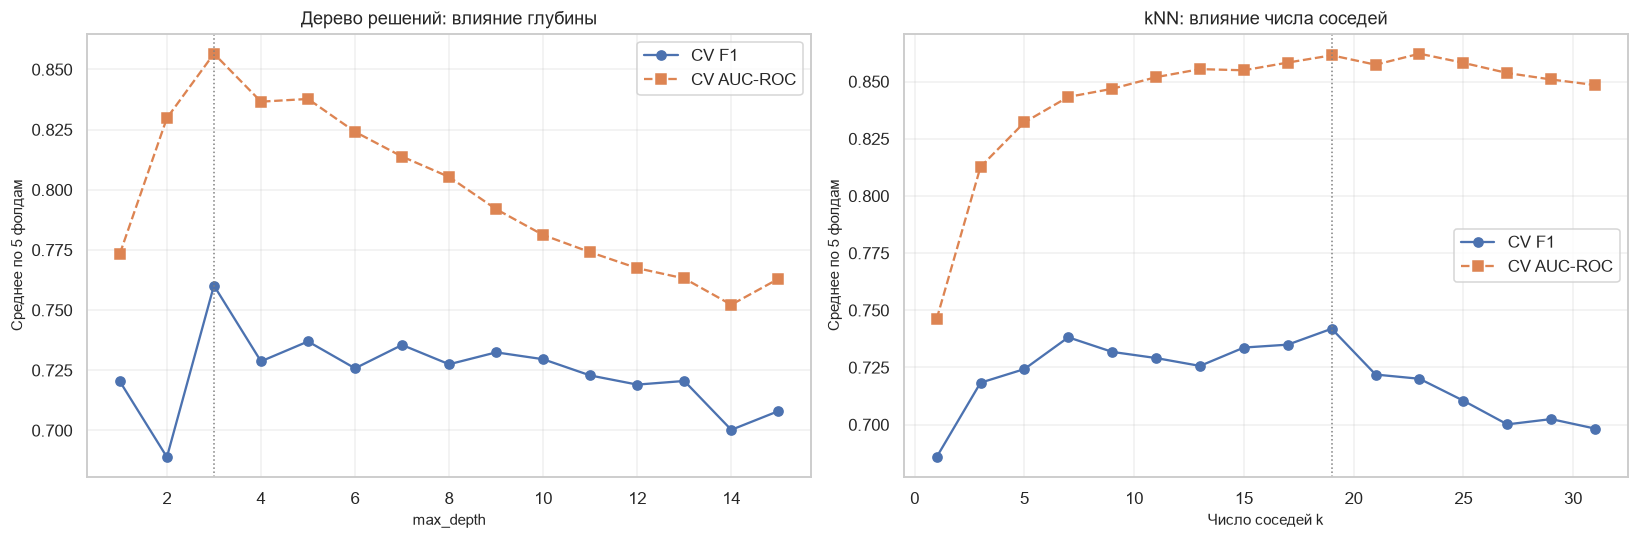

Оптимальная глубина дерева (CV F1): 3
Оптимальное k (CV F1): 19


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Влияние max_depth дерева решений ---
depths = list(range(1, 16))
dt_f1, dt_auc = [], []
for d in depths:
    pipe = Pipeline([("prep", preprocessor),
                     ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    dt_f1.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1").mean())
    dt_auc.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="roc_auc").mean())

ax = axes[0]
ax.plot(depths, dt_f1, "o-", label="CV F1", color="#4c72b0")
ax.plot(depths, dt_auc, "s--", label="CV AUC-ROC", color="#dd8452")
ax.axvline(depths[int(np.argmax(dt_f1))], color="gray", ls=":", lw=1)
ax.set_xlabel("max_depth")
ax.set_ylabel("Среднее по 5 фолдам")
ax.set_title("Дерево решений: влияние глубины")
ax.legend()
ax.grid(alpha=0.3)

# --- Влияние k в kNN ---
ks = list(range(1, 32, 2))
knn_f1, knn_auc = [], []
for k in ks:
    pipe = Pipeline([("prep", preprocessor), ("clf", KNeighborsClassifier(n_neighbors=k))])
    knn_f1.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1").mean())
    knn_auc.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="roc_auc").mean())

ax = axes[1]
ax.plot(ks, knn_f1, "o-", label="CV F1", color="#4c72b0")
ax.plot(ks, knn_auc, "s--", label="CV AUC-ROC", color="#dd8452")
ax.axvline(ks[int(np.argmax(knn_f1))], color="gray", ls=":", lw=1)
ax.set_xlabel("Число соседей k")
ax.set_ylabel("Среднее по 5 фолдам")
ax.set_title("kNN: влияние числа соседей")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "06_depth_and_k.png", bbox_inches="tight")
plt.show()

print(f"Оптимальная глубина дерева (CV F1): {depths[int(np.argmax(dt_f1))]}")
print(f"Оптимальное k (CV F1): {ks[int(np.argmax(knn_f1))]}")

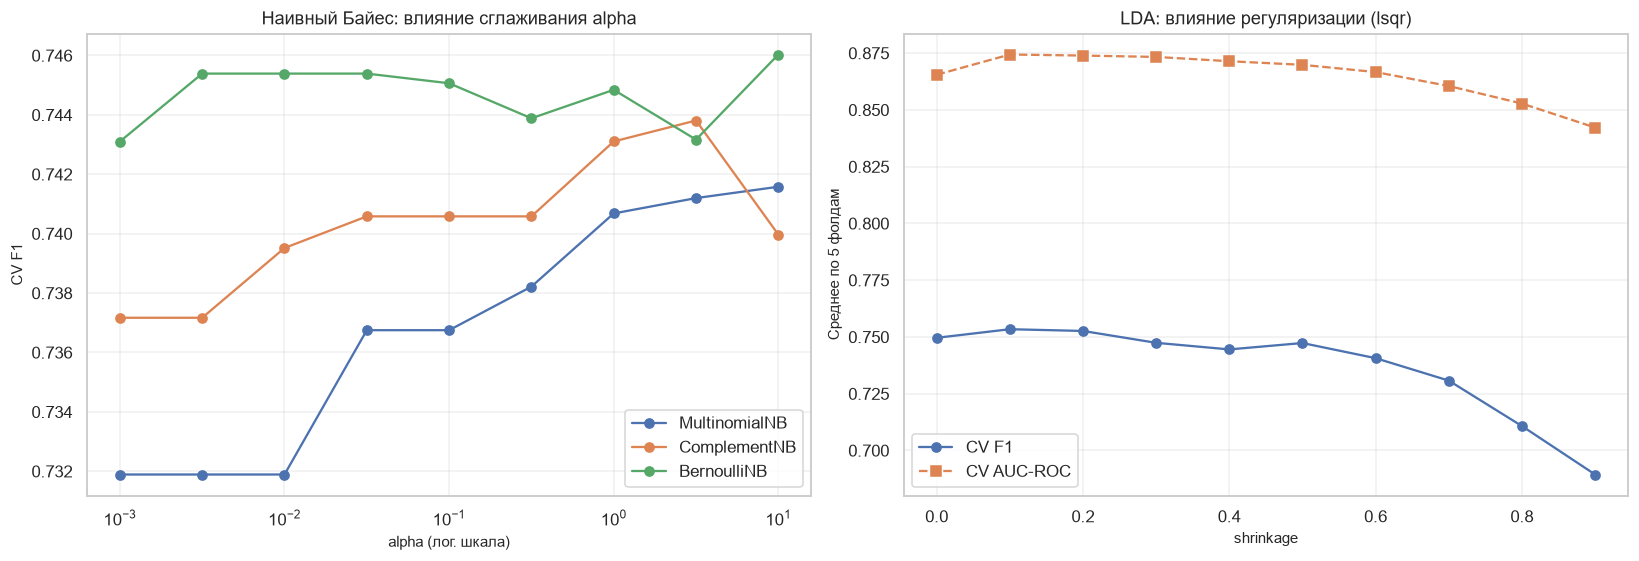

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# --- Влияние alpha для NB ---
alphas = np.logspace(-3, 1, 9)
nb_curves = {}
for label, nb_cls in [("MultinomialNB", MultinomialNB()),
                      ("ComplementNB", ComplementNB()),
                      ("BernoulliNB", BernoulliNB(binarize=0.5))]:
    scores = []
    for a in alphas:
        clf = nb_cls.__class__(**{**nb_cls.get_params(), "alpha": a})
        pipe = Pipeline([("prep", preprocessor_mm), ("clf", clf)])
        scores.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1").mean())
    nb_curves[label] = scores

ax = axes[0]
for label, scores in nb_curves.items():
    ax.plot(alphas, scores, "o-", label=label)
ax.set_xscale("log")
ax.set_xlabel("alpha (лог. шкала)")
ax.set_ylabel("CV F1")
ax.set_title("Наивный Байес: влияние сглаживания alpha")
ax.legend()
ax.grid(alpha=0.3)

# --- Влияние shrinkage для LDA ---
shrinkages = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
lda_f1, lda_auc = [], []
for s in shrinkages:
    pipe = Pipeline([("prep", preprocessor),
                     ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage=s))])
    lda_f1.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1").mean())
    lda_auc.append(cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="roc_auc").mean())

ax = axes[1]
ax.plot(shrinkages, lda_f1, "o-", label="CV F1", color="#4c72b0")
ax.plot(shrinkages, lda_auc, "s--", label="CV AUC-ROC", color="#dd8452")
ax.set_xlabel("shrinkage")
ax.set_ylabel("Среднее по 5 фолдам")
ax.set_title("LDA: влияние регуляризации (lsqr)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "07_nb_alpha_and_lda.png", bbox_inches="tight")
plt.show()

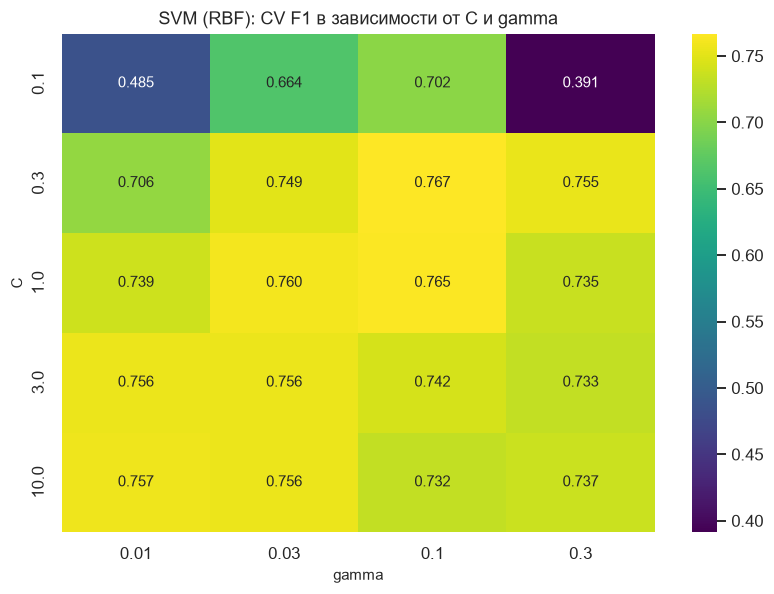

Лучшая комбинация на сетке: C=0.3, gamma=0.1, CV F1=0.7669


In [21]:
# --- Влияние C и gamma для SVM (RBF) ---
Cs = [0.1, 0.3, 1.0, 3.0, 10.0]
gammas = [0.01, 0.03, 0.1, 0.3]
svm_scores = np.zeros((len(Cs), len(gammas)))

for i, C in enumerate(Cs):
    for j, gamma in enumerate(gammas):
        pipe = Pipeline([("prep", preprocessor),
                         ("clf", SVC(kernel="rbf", C=C, gamma=gamma))])
        svm_scores[i, j] = cross_val_score(
            pipe, X_train, y_train, cv=StratifiedKFold(3, shuffle=True,
                                                       random_state=RANDOM_STATE),
            scoring="f1"
        ).mean()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(svm_scores, annot=True, fmt=".3f", cmap="viridis",
            xticklabels=gammas, yticklabels=Cs, ax=ax)
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("SVM (RBF): CV F1 в зависимости от C и gamma")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_svm_grid.png", bbox_inches="tight")
plt.show()

best_idx = np.unravel_index(np.argmax(svm_scores), svm_scores.shape)
print(f"Лучшая комбинация на сетке: C={Cs[best_idx[0]]}, gamma={gammas[best_idx[1]]}, "
      f"CV F1={svm_scores[best_idx]:.4f}")

### 5.2. Анализ влияния гиперпараметров

**Дерево решений.** CV F1 максимален при `max_depth = 3` (0.760), а при дальнейшем росте глубины качество на кросс-валидации падает: дерево запоминает шум. Полный GridSearch выбрал `entropy`, `max_depth = 4`, `min_samples_leaf = 2` и `class_weight = 'balanced'` — комбинацию ограничения глубины и минимального размера листа. Это подняло тестовый F1 с **0.672 до 0.779**, AUC — с **0.830 до 0.854**, а Recall — с 0.580 до 0.768: балансировка классов заставила дерево чаще предсказывать «выжил».

**kNN.** При `k = 1` модель переобучается; с ростом `k` CV F1 растёт и достигает максимума около **k = 19** (0.742 при равных весах), после чего выходит на плато. GridSearch выбрал `k = 21`, `weights = 'distance'`, `metric = 'euclidean'` (CV F1 = 0.753): тестовый F1 вырос с **0.731 до 0.764**, AUC — с 0.825 до 0.833. Веса по расстоянию сглаживают вклад далёких соседей и меняют оптимальное k.

**Наивный Байес.** Для MultinomialNB и ComplementNB оптимальным оказалось сильное сглаживание `alpha = 5` (на MinMax-признаках малые alpha дают нестабильные оценки), для BernoulliNB — `alpha = 0.1`, `binarize = 0.75`. Прирост невелик: F1 MultinomialNB 0.700, BernoulliNB 0.694; GaussianNB с `var_smoothing = 1e-5` поднял Accuracy до 0.777, но AUC остался на уровне 0.774. Ограничение метода — допущение о независимости признаков, а пол и класс билета сильно коррелируют с производными признаками.

**LDA.** Регуляризация `shrinkage` стабилизирует ковариационную матрицу; GridSearch выбрал `solver = 'lsqr', shrinkage = 'auto'`. На тесте F1 (0.788) и AUC (0.859) практически совпали с нерегулируемой LDA (0.797 / 0.862): данных достаточно, а признаки после масштабирования хорошо обусловлены. Это пример того, что подбор не всегда улучшает hold-out: выигрыш виден на CV, но разница на тесте лежит в пределах шума.

**SVM.** На heatmap виден оптимум в области небольших `C` (0.3) и `gamma` ≈ 0.03–0.1. Полный GridSearch выбрал RBF-ядро, `C = 0.3`, `gamma = 'scale'` (≈ 0.08 для 29 преобразованных признаков) с CV F1 = 0.768. Тестовые метрики почти не изменились (F1 0.773 против 0.775 у baseline): стартовая конфигурация уже была близка к оптимуму. Слишком большие `C` и `gamma` ведут к переобучению, слишком малое `C` — к недообучению.

**Итог по подбору.** GridSearch заметно улучшил модели, далёкие от оптимума (дерево, kNN), и почти не изменил LDA/SVM. Лучший CV F1 — у SVM (0.768) и дерева (0.767); на независимом тесте лидирует LDA.

## 6. Нейронная сеть на TensorFlow/Keras

### 6.1. Архитектура baseline-модели

| Компонент | Значение |
|:---|:---|
| Вход | вектор после `ColumnTransformer` (числовые + one-hot) |
| Скрытые слои | `Dense(32, relu)` → `Dropout(0.2)` → `Dense(16, relu)` → `Dropout(0.2)` |
| Выход | `Dense(1, sigmoid)` — вероятность выживания |
| Функция потерь | `binary_crossentropy` |
| Оптимизатор | `Adam(learning_rate=1e-3)` |
| Метрики | `accuracy`, `AUC` |
| Регуляризация | Dropout + EarlyStopping по `val_loss` (patience=12, восстановление лучших весов) |
| Дисбаланс | `class_weight` обратно пропорционально частотам классов |
| Валидация | 20 % обучающей выборки |
| TensorBoard | `logs_tb_titanic/baseline`: scalars, histograms весов, graph |

`class_weight` компенсирует умеренный дисбаланс (≈62 % / 38 %): без него сеть склонна чаще предсказывать класс большинства.

In [22]:
# Матрицы для нейросети: препроцессор обучается только на train
X_train_nn = preprocessor.fit_transform(X_train).astype("float32")
X_test_nn = preprocessor.transform(X_test).astype("float32")

print("X_train_nn:", X_train_nn.shape, "| X_test_nn:", X_test_nn.shape)

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print("class_weight:", {k: round(v, 4) for k, v in class_weight.items()})

X_train_nn: (712, 29) | X_test_nn: (179, 29)
class_weight: {0: 0.8109, 1: 1.304}


In [23]:
def build_nn(input_dim, hidden=(32, 16), activation="relu", dropout=0.2,
             lr=1e-3, optimizer="adam", l2=0.0):
    keras.backend.clear_session()
    tf.random.set_seed(RANDOM_STATE)

    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden:
        model.add(layers.Dense(
            units, activation=activation,
            kernel_regularizer=keras.regularizers.l2(l2) if l2 > 0 else None
        ))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))

    optimizers = {
        "adam": keras.optimizers.Adam(learning_rate=lr),
        "sgd": keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
        "rmsprop": keras.optimizers.RMSprop(learning_rate=lr),
    }
    model.compile(
        optimizer=optimizers[optimizer],
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model


def train_nn(run_name, hidden=(32, 16), activation="relu", dropout=0.2,
             lr=1e-3, optimizer="adam", batch_size=32, epochs=80,
             patience=12, verbose=0):
    model = build_nn(X_train_nn.shape[1], hidden=hidden, activation=activation,
                     dropout=dropout, lr=lr, optimizer=optimizer)

    log_path = LOG_DIR / run_name
    callbacks = [
        keras.callbacks.TensorBoard(log_dir=str(log_path),
                                    histogram_freq=1, write_graph=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                      restore_best_weights=True),
    ]

    history = model.fit(
        X_train_nn, y_train.values,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weight,
        shuffle=True,
        verbose=verbose,
        callbacks=callbacks,
    )

    proba = model.predict(X_test_nn, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)

    result = {
        "Run": run_name,
        "Hidden": str(hidden),
        "Activation": activation,
        "LR": lr,
        "Optimizer": optimizer,
        "Batch": batch_size,
        "Dropout": dropout,
        "Epochs_run": len(history.history["loss"]),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
        "Best_val_loss": min(history.history["val_loss"]),
        "Best_val_acc": max(history.history["val_accuracy"]),
        "history": history.history,
        "model": model,
        "proba": proba,
        "pred": pred,
    }
    return result

### 6.2. Обучение baseline-сети

In [24]:
baseline_nn = train_nn("baseline", hidden=(32, 16), activation="relu", dropout=0.2,
                       lr=1e-3, optimizer="adam", batch_size=32, epochs=80, verbose=2)

print("\nBaseline NN на тесте:")
print(f"  Accuracy = {baseline_nn['Accuracy']:.4f}")
print(f"  Precision = {baseline_nn['Precision']:.4f}")
print(f"  Recall = {baseline_nn['Recall']:.4f}")
print(f"  F1 = {baseline_nn['F1']:.4f}")
print(f"  AUC-ROC = {baseline_nn['AUC-ROC']:.4f}")
print(f"  Эпох обучения: {baseline_nn['Epochs_run']}")

print("\nАрхитектура:")
baseline_nn["model"].summary()

Epoch 1/80


18/18 - 2s - 101ms/step - accuracy: 0.5800 - auc: 0.5468 - loss: 0.7037 - val_accuracy: 0.6364 - val_auc: 0.6852 - val_loss: 0.6555


Epoch 2/80


18/18 - 0s - 13ms/step - accuracy: 0.6626 - auc: 0.6873 - loss: 0.6469 - val_accuracy: 0.6503 - val_auc: 0.7554 - val_loss: 0.6226


Epoch 3/80


18/18 - 0s - 12ms/step - accuracy: 0.6766 - auc: 0.7495 - loss: 0.6100 - val_accuracy: 0.6923 - val_auc: 0.8000 - val_loss: 0.5894


... (53 outputs left out)

 Total params: 4,517 (17.65 KB)

 Trainable params: 1,505 (5.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,012 (11.77 KB)

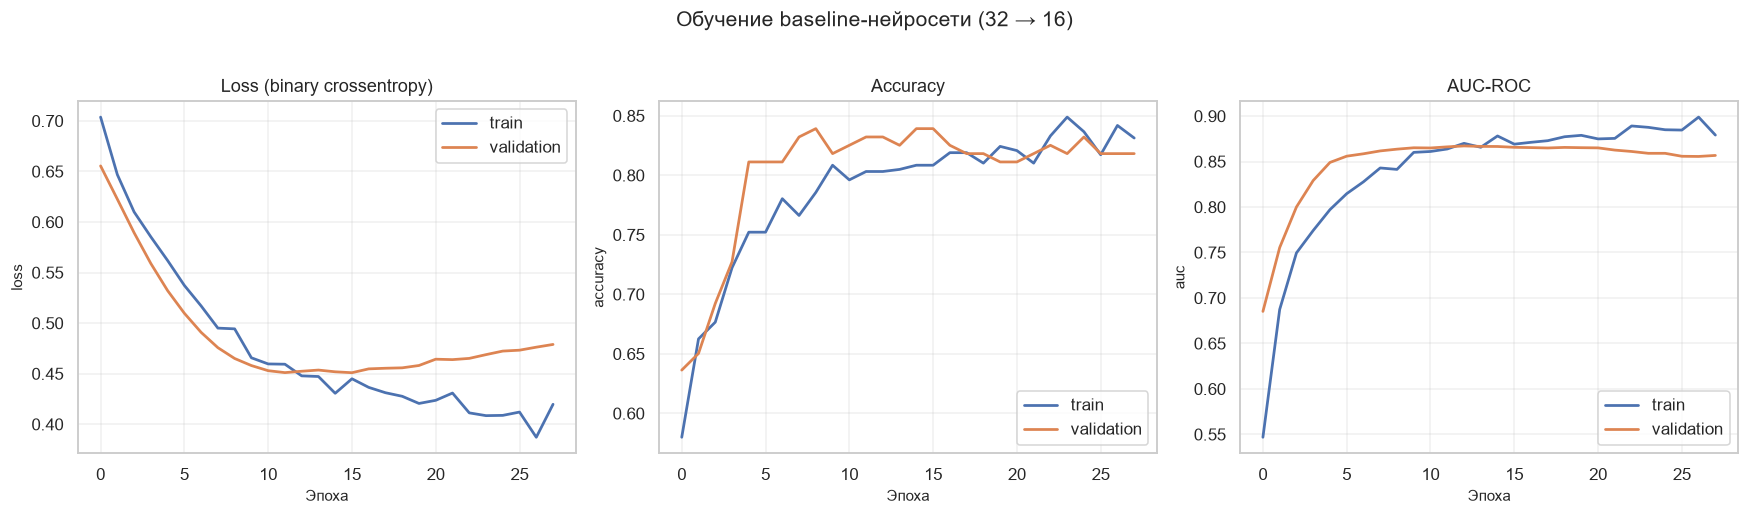

In [25]:
h = baseline_nn["history"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, metric, title in zip(axes,
                             ["loss", "accuracy", "auc"],
                             ["Loss (binary crossentropy)", "Accuracy", "AUC-ROC"]):
    ax.plot(h[metric], label="train", lw=1.8)
    ax.plot(h["val_" + metric], label="validation", lw=1.8)
    ax.set_title(title)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("Обучение baseline-нейросети (32 → 16)", fontsize=14, y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_nn_baseline_curves.png", bbox_inches="tight")
plt.show()

### 6.3. Эксперименты с гиперпараметрами нейронной сети

Исследуется влияние на качество:

1. **архитектуры** — число слоёв и нейронов: (8), (32,16), (64,32), (128,64,32);
2. **функции активации** — `relu` vs `tanh`;
3. **скорости обучения** — 1e-4, 1e-3, 1e-2;
4. **оптимизатора** — Adam, SGD (momentum=0.9), RMSprop;
5. **размера батча** — 32 vs 128;
6. **регуляризации** — Dropout 0.2 vs 0.5;
7. **числа эпох** — ограничение 5, 15 и 80 эпох (при EarlyStopping).

Каждый запуск логируется в отдельный подкаталог `logs_tb_titanic/<run_name>`, поэтому в TensorBoard кривые можно накладывать и сравнивать.

In [26]:
experiments = [
    dict(run_name="exp_shallow_8", hidden=(8,)),
    dict(run_name="exp_wide_64_32", hidden=(64, 32)),
    dict(run_name="exp_deep_128_64_32", hidden=(128, 64, 32)),
    dict(run_name="exp_tanh", hidden=(32, 16), activation="tanh"),
    dict(run_name="exp_lr_0.0001", hidden=(32, 16), lr=1e-4),
    dict(run_name="exp_lr_0.01", hidden=(32, 16), lr=1e-2),
    dict(run_name="exp_sgd", hidden=(32, 16), optimizer="sgd", lr=1e-2),
    dict(run_name="exp_rmsprop", hidden=(32, 16), optimizer="rmsprop"),
    dict(run_name="exp_batch_128", hidden=(32, 16), batch_size=128),
    dict(run_name="exp_dropout_0.5", hidden=(32, 16), dropout=0.5),
    dict(run_name="exp_epochs_5", hidden=(32, 16), epochs=5),
    dict(run_name="exp_epochs_15", hidden=(32, 16), epochs=15),
]

nn_runs = {"baseline": baseline_nn}
for cfg in experiments:
    cfg = dict(cfg)
    name = cfg.pop("run_name")
    nn_runs[name] = train_nn(name, **cfg)
    print(f"{name:22s} -> epochs={nn_runs[name]['Epochs_run']:2d} | "
          f"F1={nn_runs[name]['F1']:.4f} | AUC={nn_runs[name]['AUC-ROC']:.4f} | "
          f"Acc={nn_runs[name]['Accuracy']:.4f}")

nn_df = pd.DataFrame([
    {k: v for k, v in run.items()
     if k not in ("history", "model", "proba", "pred")}
    for run in nn_runs.values()
]).set_index("Run")

nn_df.round(4).sort_values("F1", ascending=False)

exp_shallow_8          -> epochs=47 | F1=0.7310 | AUC=0.8514 | Acc=0.7821


exp_wide_64_32         -> epochs=22 | F1=0.7639 | AUC=0.8572 | Acc=0.8101


exp_deep_128_64_32     -> epochs=17 | F1=0.7333 | AUC=0.8381 | Acc=0.7765


exp_tanh               -> epochs=27 | F1=0.7483 | AUC=0.8568 | Acc=0.7933


exp_lr_0.0001          -> epochs=80 | F1=0.7483 | AUC=0.8157 | Acc=0.7933


exp_lr_0.01            -> epochs=14 | F1=0.7671 | AUC=0.8476 | Acc=0.8101


... (3 outputs left out)

exp_dropout_0.5        -> epochs=39 | F1=0.7518 | AUC=0.8627 | Acc=0.8045


exp_epochs_5           -> epochs= 5 | F1=0.7013 | AUC=0.8030 | Acc=0.7430


exp_epochs_15          -> epochs=15 | F1=0.7467 | AUC=0.8426 | Acc=0.7877


,Hidden,Activation,LR,Optimizer,Batch,Dropout,Epochs_run,Accuracy,Precision,Recall,F1,AUC-ROC,Best_val_loss,Best_val_acc
Run,,,,,,,,,,,,,,
exp_lr_0.01,"(32, 16)",relu,0.0100,adam,32,0.2,14,0.8101,0.7273,0.8116,0.7671,0.8476,0.4595,0.8182
exp_wide_64_32,"(64, 32)",relu,0.0010,adam,32,0.2,22,0.8101,0.7333,0.7971,0.7639,0.8572,0.4558,0.8252
exp_sgd,"(32, 16)",relu,0.0100,sgd,32,0.2,19,0.8156,0.7647,0.7536,0.7591,0.8561,0.4706,0.8252
exp_dropout_0.5,"(32, 16)",relu,0.0010,adam,32,0.5,39,0.8045,0.7361,0.7681,0.7518,0.8627,0.4612,0.8112
exp_tanh,"(32, 16)",tanh,0.0010,adam,32,0.2,27,0.7933,0.7051,0.7971,0.7483,0.8568,0.4478,0.8182
exp_lr_0.0001,"(32, 16)",relu,0.0001,adam,32,0.2,80,0.7933,0.7051,0.7971,0.7483,0.8157,0.4654,0.8252
exp_epochs_15,"(32, 16)",relu,0.0010,adam,32,0.2,15,0.7877,0.6914,0.8116,0.7467,0.8426,0.4565,0.8252
exp_rmsprop,"(32, 16)",relu,0.0010,rmsprop,32,0.2,33,0.7933,0.7162,0.7681,0.7413,0.8451,0.4508,0.8252
exp_batch_128,"(32, 16)",relu,0.0010,adam,128,0.2,40,0.7765,0.6706,0.8261,0.7403,0.8659,0.4578,0.7972


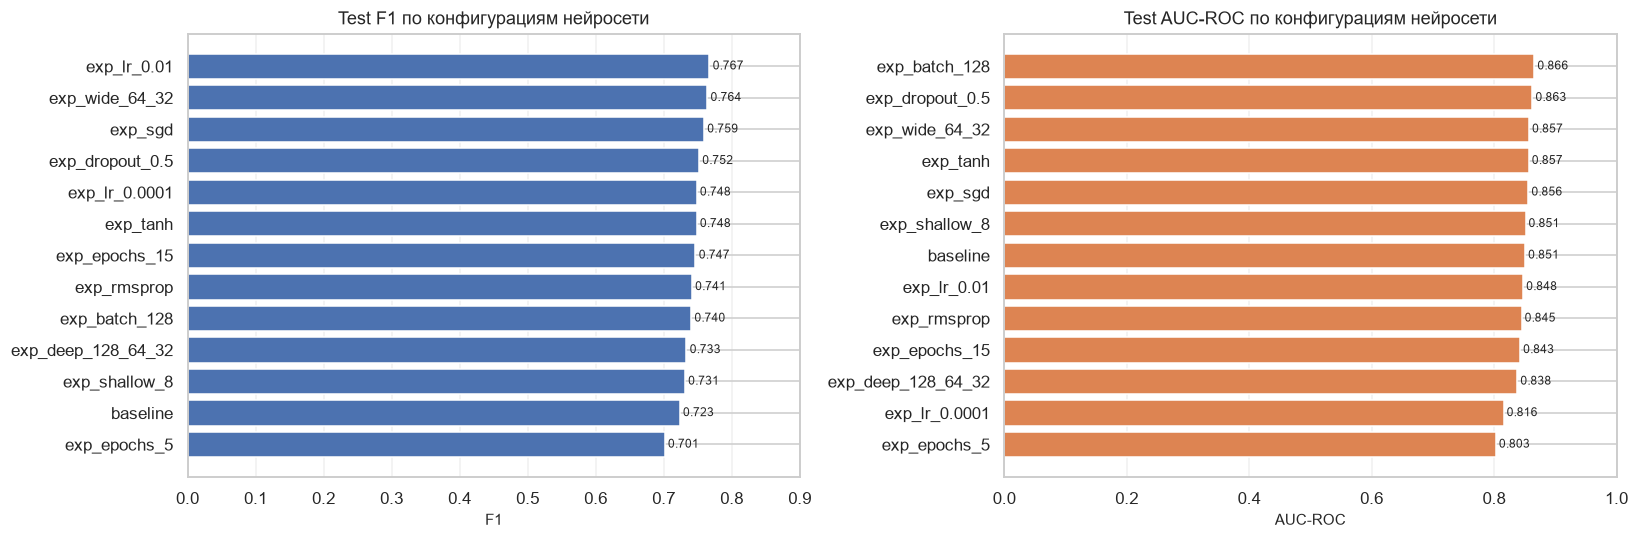

In [27]:
# Сравнение конфигураций нейросети
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_df = nn_df.sort_values("F1")
ax = axes[0]
ax.barh(plot_df.index, plot_df["F1"], color="#4c72b0")
ax.set_xlim(0, max(0.9, plot_df["F1"].max() * 1.15))
ax.set_title("Test F1 по конфигурациям нейросети")
ax.set_xlabel("F1")
ax.grid(axis="x", alpha=0.3)
for i, v in enumerate(plot_df["F1"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)

plot_df = nn_df.sort_values("AUC-ROC")
ax = axes[1]
ax.barh(plot_df.index, plot_df["AUC-ROC"], color="#dd8452")
ax.set_xlim(0, 1.0)
ax.set_title("Test AUC-ROC по конфигурациям нейросети")
ax.set_xlabel("AUC-ROC")
ax.grid(axis="x", alpha=0.3)
for i, v in enumerate(plot_df["AUC-ROC"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "10_nn_experiments.png", bbox_inches="tight")
plt.show()

### 6.3.1. Анализ экспериментов с нейросетью

- **Глубина и ширина.** Лучший F1 среди дополнительных конфигураций — у `lr = 1e-2` (0.767) и архитектуры `(64, 32)` (0.764). Слишком узкая сеть `(8,)` (F1 0.731) и слишком глубокая `(128, 64, 32)` (F1 0.733, AUC 0.838) проигрывают: на 712 обучающих объектах глубокая сеть переобучается, а узкой не хватает ёмкости.
- **Функция активации.** `tanh` даёт F1 0.748 и AUC 0.857 — немного лучше baseline по F1, но разница в пределах шума.
- **Learning rate.** `lr = 1e-2` сходится за 14 эпох и даёт лучший F1 (0.767); `lr = 1e-4` за 80 эпох не успевает выйти на плато (AUC 0.816) — типичное недообучение. `lr = 1e-3` (baseline) — компромисс по стабильности.
- **Оптимизатор.** SGD с `momentum=0.9` даёт самую высокую Accuracy (0.816) и F1 0.759, RMSprop — F1 0.741. Adam остаётся удобным выбором по умолчанию.
- **Размер батча.** Увеличение до 128 снижает F1 (0.740), но даёт максимальный AUC (0.866): более шумные обновления работают как регуляризация и улучшают ранжирование, хотя сдвигают оптимальный порог.
- **Dropout.** 0.5 повышает AUC (0.863) и F1 (0.752) относительно 0.2 — более сильная регуляризация полезна при малом объёме данных.
- **Число эпох.** 5 эпох явно недостаточно (F1 0.701, AUC 0.803); 15 эпох (F1 0.747, AUC 0.843) уже близко к лучшим результатам, а EarlyStopping на baseline остановил обучение на 28-й эпохе.

Таким образом, для Titanic нейросеть требует аккуратной настройки и всё равно не превосходит LDA по F1; её сильная сторона — высокий AUC при удачном выборе батча и регуляризации.

### 6.4. Влияние скорости обучения и числа эпох

Сравним кривые валидационного loss для трёх значений learning rate. Слишком большой шаг даёт быструю, но нестабильную сходимость (рывки, возможное расхождение), слишком маленький — медленное обучение, при котором EarlyStopping успевает остановить модель до выхода на плато.

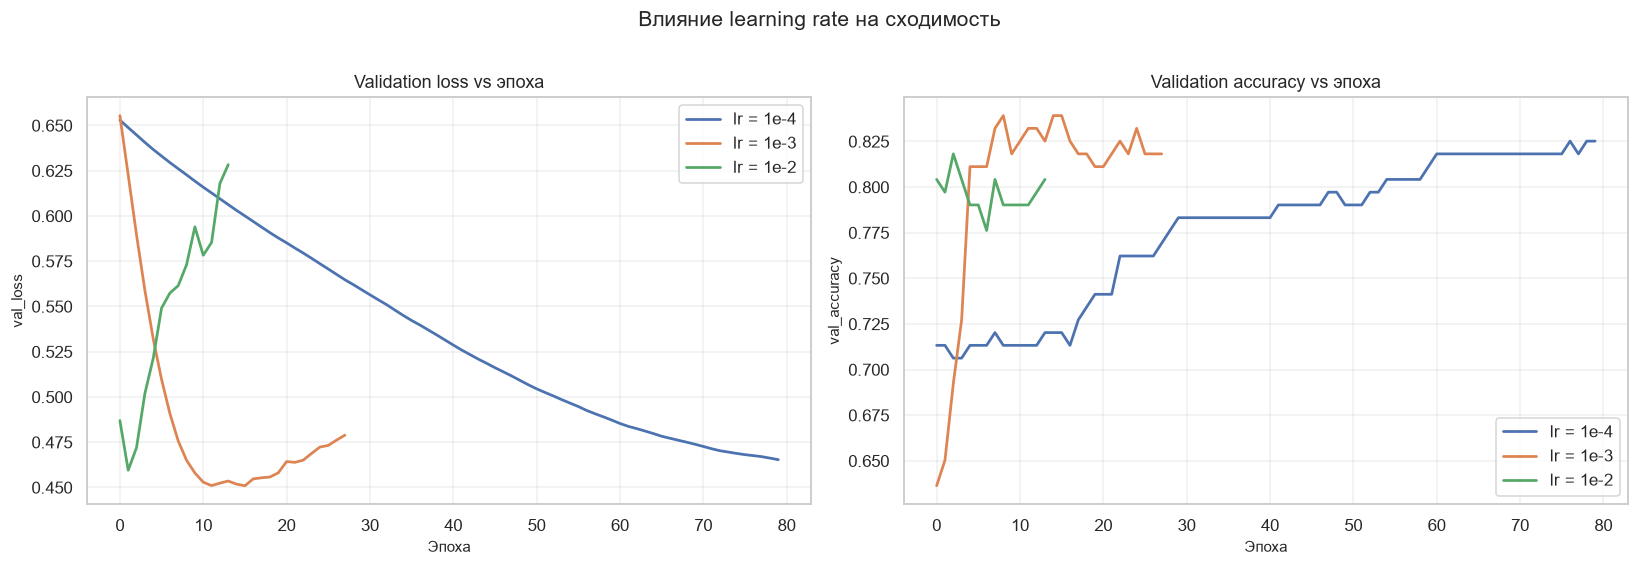

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

lr_runs = [("exp_lr_0.0001", "lr = 1e-4"), ("baseline", "lr = 1e-3"), ("exp_lr_0.01", "lr = 1e-2")]
for run_name, label in lr_runs:
    hist = nn_runs[run_name]["history"]
    axes[0].plot(hist["val_loss"], lw=1.8, label=label)
    axes[1].plot(hist["val_accuracy"], lw=1.8, label=label)

axes[0].set_title("Validation loss vs эпоха")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("val_loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation accuracy vs эпоха")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("val_accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("Влияние learning rate на сходимость", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "11_nn_learning_rate.png", bbox_inches="tight")
plt.show()

### 6.5. Мониторинг обучения в TensorBoard

Все запуски пишут логи в `logs_tb_titanic/`:

```
logs_tb_titanic/
  baseline/
  exp_shallow_8/
  exp_wide_64_32/
  exp_deep_128_64_32/
  exp_tanh/
  exp_lr_0.0001/
  exp_lr_0.01/
  exp_sgd/
  exp_rmsprop/
  exp_batch_128/
  exp_dropout_0.5/
  exp_epochs_5/
  exp_epochs_15/
```

Запуск:

```bash
tensorboard --logdir logs_tb_titanic --port 6006
```

Затем открыть http://localhost:6006. В интерфейсе доступны:

1. **Scalars** — `epoch_loss`, `epoch_accuracy`, `epoch_auc` для train и validation; удобно сравнивать все run'ы одновременно (переключатель runs слева).
2. **Histograms** — распределения весов и смещений по эпохам (`histogram_freq=1`): видно, как слои «настраиваются» и не происходит ли взрыв весов.
3. **Graphs** — вычислительный граф Keras-модели (слои, связи, размерности).
4. **Distributions** — распределения тензоров по эпохам.

Что видно на практике: `val_loss` обычно достигает минимума за 15–30 эпох; EarlyStopping с `patience=12` останавливает обучение до начала устойчивого переобучения. При `lr=1e-2` кривые шумнее, при `lr=1e-4` сходимость медленнее.

#### Экспортированные из TensorBoard графики

Чтобы графики обучения можно было посмотреть без запуска TensorBoard, скалярные ряды из event-файлов выгружены скриптом `export_tensorboard.py` в каталог `logs/`:

| Файл | Что содержит |
|:---|:---|
| `logs/tensorboard_baseline_curves.png` | Loss, accuracy и AUC для baseline-модели: train и validation на одном поле, отмечена эпоха с минимальным `val_loss` |
| `logs/tensorboard_learning_rate.png` | Влияние learning rate (1e-3, 1e-2, 1e-4) на validation loss и accuracy |
| `logs/tensorboard_runs_comparison.png` | Сравнение пяти конфигураций сети по `val_loss` и `val_AUC` |
| `logs/tensorboard_scalars.csv` | Полные числовые ряды (run, split, epoch, loss, accuracy, auc, lr) — те же данные, что показывает вкладка Scalars |

**1. Baseline: обучение и валидация.** По оси X — номер эпохи, по оси Y — значение метрики; синяя кривая — обучение, красная — валидация, пунктир — эпоха с минимальным `val_loss`.

![Кривые baseline в TensorBoard](logs/tensorboard_baseline_curves.png)

На графике loss видно, что train_loss монотонно убывает на протяжении всех 28 эпох, а val_loss достигает минимума **0.451 на 16-й эпохе** (val_accuracy 0.839, val_AUC 0.866), после чего начинает расти: к 28-й эпохе val_loss = 0.479, val_accuracy падает до 0.818. Это классическая картина переобучения — именно на 16-й эпохе EarlyStopping сохранил лучшие веса и вернул их в модель. Разрыв между train и validation кривыми после 16-й эпохи увеличивается, что подтверждает необходимость регуляризации (Dropout) и ранней остановки.

**2. Влияние learning rate.** Сравниваются три запуска с одинаковой архитектурой и разной скоростью обучения; показаны только validation-кривые, чтобы наглядно увидеть сходимость.

![Сравнение learning rate](logs/tensorboard_learning_rate.png)

- `lr = 1e-3` (baseline) — плавная сходимость, минимум `val_loss = 0.451` на 16-й эпохе;
- `lr = 1e-2` — очень быстрый старт (минимум 0.460 уже на 2-й эпохе), но кривая шумная и нестабильная: слишком большой шаг «перескакивает» оптимум, поэтому итоговое качество не выше baseline;
- `lr = 1e-4` — сходимость слишком медленная: минимум 0.465 достигается только к 80-й эпохе, и accuracy остаётся ниже, чем у baseline.

Вывод: для данного датасета и архитектуры `1e-3` — компромисс между скоростью и устойчивостью; `1e-2` приводит к осцилляциям, `1e-4` требует неоправданно много эпох.

**3. Сравнение конфигураций.** На двух панелях — `val_loss` и `val_AUC` для пяти запусков: baseline (32→16), (64→32), Dropout 0.5, batch 128 и SGD с momentum.

![Сравнение запусков](logs/tensorboard_runs_comparison.png)

- **Dropout 0.5** даёт лучший `val_AUC = 0.882` и держит валидационную ошибку низкой дольше остальных (обучение идёт до 39-й эпохи) — сильная регуляризация помогает при малом объёме данных;
- **batch 128** обеспечивает более гладкие кривые и `val_AUC = 0.875` к 28-й эпохе: усреднение по большей выборке снижает шум градиента;
- расширение сети до **(64→32)** ускоряет рост AUC в начале (максимум 0.872 уже на 10-й эпохе), но раньше начинает переобучаться;
- **SGD с momentum** заметно отстаёт (`max val_AUC = 0.850`): без адаптивного шага обучение сходится быстрее по эпохам (7 эпох), но в худшую точку.

Таким образом, экспортированные графики повторяют то, что видно во вкладке **Scalars** TensorBoard, и позволяют документировать динамику обучения прямо в ноутбуке. Гистограммы весов и граф модели остаются доступны только в интерактивном интерфейсе TensorBoard (`tensorboard --logdir logs_tb_titanic`).


In [29]:
# Проверка, что логи TensorBoard действительно записаны
log_size = {}
for run_dir in sorted(LOG_DIR.glob("*")):
    if run_dir.is_dir():
        log_size[run_dir.name] = round(
            sum(p.stat().st_size for p in run_dir.rglob("*") if p.is_file()) / 1024, 1
        )

pd.DataFrame({"run": list(log_size.keys()),
              "размер логов, КБ": list(log_size.values())})

,run,"размер логов, КБ"
0,baseline,160.1
1,exp_batch_128,226.7
2,exp_deep_128_64_32,127.3
3,exp_dropout_0.5,221.2
4,exp_epochs_15,87.8
5,exp_epochs_5,32.2
6,exp_lr_0.0001,449.1
7,exp_lr_0.01,82.3
8,exp_rmsprop,187.9
9,exp_sgd,110.0


## 7. Сравнительный анализ

Соберём в одну таблицу базовые классификаторы, модели после GridSearchCV и лучшую нейросеть.

In [30]:
comparison_rows = []

for name, row in baseline_df.iterrows():
    comparison_rows.append({
        "Model": name, "Group": "baseline (sklearn)",
        "Accuracy": row["Accuracy"], "Precision": row["Precision"],
        "Recall": row["Recall"], "F1": row["F1"], "AUC-ROC": row["AUC-ROC"],
    })

for name, row in tuned_df.iterrows():
    comparison_rows.append({
        "Model": name + " (tuned)", "Group": "GridSearchCV",
        "Accuracy": row["Accuracy"], "Precision": row["Precision"],
        "Recall": row["Recall"], "F1": row["F1"], "AUC-ROC": row["AUC-ROC"],
    })

best_nn_name = nn_df["F1"].idxmax()
best_nn = nn_runs[best_nn_name]
comparison_rows.append({
    "Model": f"NN ({best_nn_name})", "Group": "TensorFlow",
    "Accuracy": best_nn["Accuracy"], "Precision": best_nn["Precision"],
    "Recall": best_nn["Recall"], "F1": best_nn["F1"], "AUC-ROC": best_nn["AUC-ROC"],
})

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")

comparison_df.round(4).sort_values("F1", ascending=False)

,Group,Accuracy,Precision,Recall,F1,AUC-ROC
Model,,,,,,
LDA,baseline (sklearn),0.8492,0.8281,0.7681,0.7970,0.8623
LDA (tuned),GridSearchCV,0.8436,0.8254,0.7536,0.7879,0.8594
DecisionTree (tuned),GridSearchCV,0.8324,0.7910,0.7681,0.7794,0.8543
SVM,baseline (sklearn),0.8380,0.8333,0.7246,0.7752,0.8528
SVM (tuned),GridSearchCV,0.8324,0.8095,0.7391,0.7727,0.8505
NN (exp_lr_0.01),TensorFlow,0.8101,0.7273,0.8116,0.7671,0.8476
kNN (tuned),GridSearchCV,0.8101,0.7333,0.7971,0.7639,0.8329
GaussianNB (tuned),GridSearchCV,0.7765,0.6629,0.8551,0.7468,0.7736
GaussianNB,baseline (sklearn),0.7654,0.6484,0.8551,0.7375,0.7742


In [31]:
# Сохраним итоговые таблицы рядом с ноутбуком — пригодятся для отчёта
RESULT_DIR = Path("results_titanic")
RESULT_DIR.mkdir(exist_ok=True)

baseline_df.round(4).to_csv(RESULT_DIR / "baseline_metrics.csv")
tuned_df.round(4).to_csv(RESULT_DIR / "tuned_metrics.csv")
nn_df.round(4).to_csv(RESULT_DIR / "nn_experiments.csv")
comparison_df.round(4).sort_values("F1", ascending=False).to_csv(RESULT_DIR / "comparison.csv")

print("Таблицы сохранены в", RESULT_DIR.resolve())
for p in sorted(RESULT_DIR.glob("*.csv")):
    print(" -", p.name)

Таблицы сохранены в D:\NGTU\4_Kyrs\6_semestr\II_interface\laba_2\results_titanic
 - baseline_metrics.csv
 - comparison.csv
 - nn_experiments.csv
 - tuned_metrics.csv


### 7.1. Интерпретация результатов

| Критерий | Лучшая модель | Значение |
|:---|:---|---:|
| Accuracy | LDA (baseline) | 0.849 |
| Precision | SVM (baseline) | 0.833 |
| Recall | GaussianNB | 0.855 |
| **F1-score** | **LDA (baseline)** | **0.797** |
| **AUC-ROC** | **LDA (baseline)** | **0.862** |
| AUC-ROC (среди всех запусков) | NN, batch = 128 | 0.866 |

- **LDA — лучшая модель по совокупности метрик.** Линейная граница в 29-мерном пространстве one-hot/масштабированных признаков даёт Accuracy 0.849, F1 0.797 и AUC 0.862. Это ожидаемо: после кодирования пола, класса, титула и палубы классы становятся почти линейно разделимыми, а объёма данных (712 объектов в train) недостаточно для сложных нелинейных моделей.
- **Дерево после подбора** (F1 0.779, AUC 0.854) и **SVM** (F1 0.775, AUC 0.853) — следующие по качеству. Дерево выигрывает в интерпретируемости, SVM — в Precision.
- **Нейросеть** после настройки достигает F1 0.767 при AUC 0.866 (лучший AUC среди всех запусков — конфигурация с `batch = 128`). Однако по F1 она уступает LDA: 712 объектов недостаточно, чтобы сложная модель оправдала себя.
- **GaussianNB** — выбор, если критичен Recall (0.855): он находит подавляющее большинство выживших, но даёт много ложных срабатываний (Precision 0.648).
- **Эффект подбора гиперпараметров** неоднороден: дерево прибавило +0.107 F1, kNN — +0.033, а LDA и SVM остались на прежнем уровне (различия в пределах шума). GridSearch оптимизирует CV-оценку, и на независимой тестовой выборке из 179 объектов выигрыш не гарантирован.

**Практическая рекомендация.** Если нужен максимальный F1/Accuracy и интерпретируемые коэффициенты — **LDA**. Если важнее полнота (не пропустить выжившего) — **GaussianNB** или дерево с `class_weight='balanced'`. Если нужен максимальный AUC для ранжирования — нейросеть с большим батчем или LDA; для продакшена на таких данных проще и надёжнее LDA.

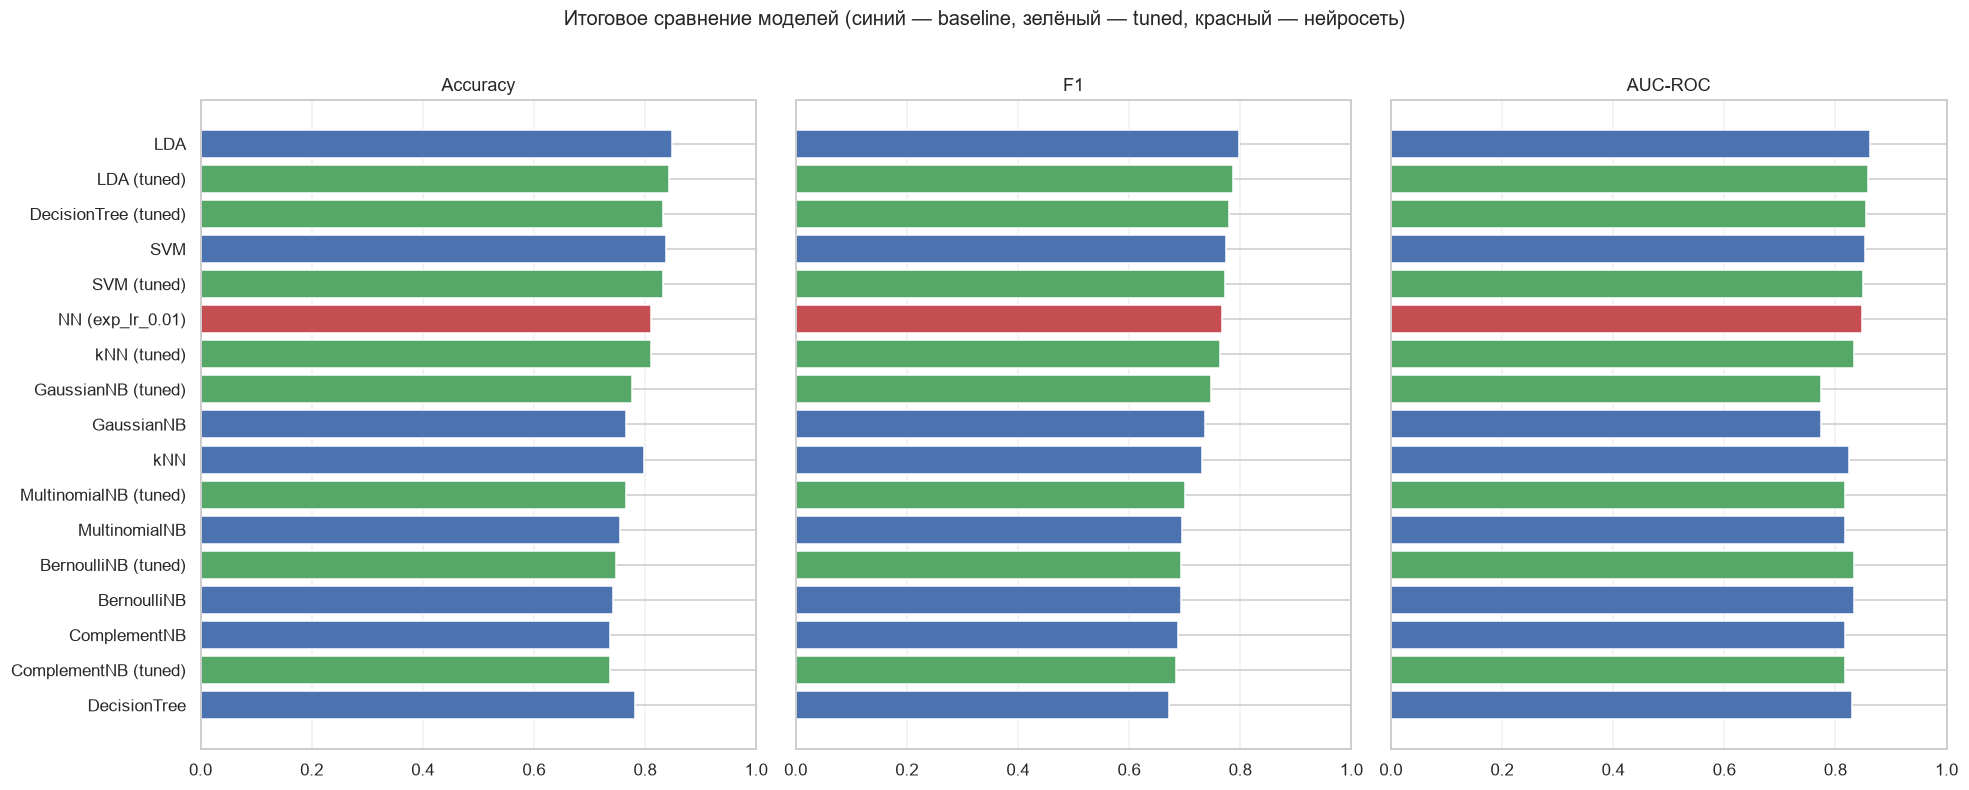

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
plot_df = comparison_df.sort_values("F1")

for ax, metric in zip(axes, ["Accuracy", "F1", "AUC-ROC"]):
    colors = plot_df["Group"].map({
        "baseline (sklearn)": "#4c72b0",
        "GridSearchCV": "#55a868",
        "TensorFlow": "#c44e52",
    })
    ax.barh(plot_df.index, plot_df[metric], color=colors)
    ax.set_xlim(0, 1.0)
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)

axes[0].set_ylabel("")
fig.suptitle("Итоговое сравнение моделей (синий — baseline, зелёный — tuned, красный — нейросеть)",
             fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "12_comparison_all.png", bbox_inches="tight")
plt.show()

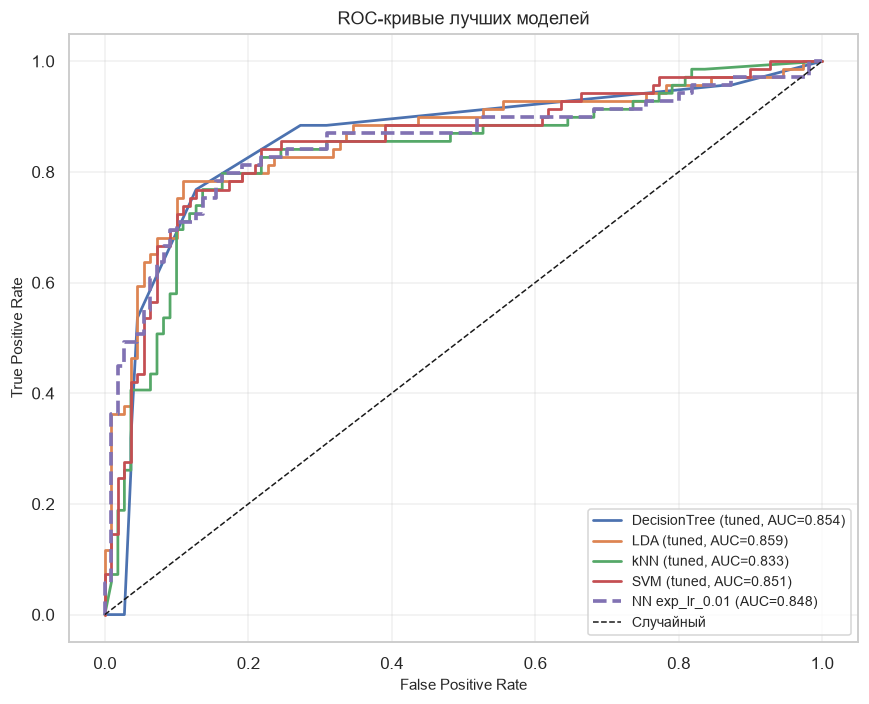

In [33]:
# ROC-кривые лучших моделей каждого семейства
best_classical = tuned_df["AUC-ROC"].idxmax()
best_tree = tuned_df.loc["DecisionTree", "AUC-ROC"]
best_svm = tuned_df.loc["SVM", "AUC-ROC"]
best_knn = tuned_df.loc["kNN", "AUC-ROC"]
best_lda = tuned_df.loc["LDA", "AUC-ROC"]

fig, ax = plt.subplots(figsize=(8, 6.5))

for name in ["DecisionTree", "LDA", "kNN", "SVM"]:
    fpr, tpr, _ = roc_curve(y_test, tuned_probas[name])
    ax.plot(fpr, tpr, lw=1.8,
            label=f"{name} (tuned, AUC={tuned_df.loc[name, 'AUC-ROC']:.3f})")

fpr, tpr, _ = roc_curve(y_test, best_nn["proba"])
ax.plot(fpr, tpr, lw=2.4, ls="--",
        label=f"NN {best_nn_name} (AUC={best_nn['AUC-ROC']:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Случайный")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривые лучших моделей")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "13_roc_best.png", bbox_inches="tight")
plt.show()

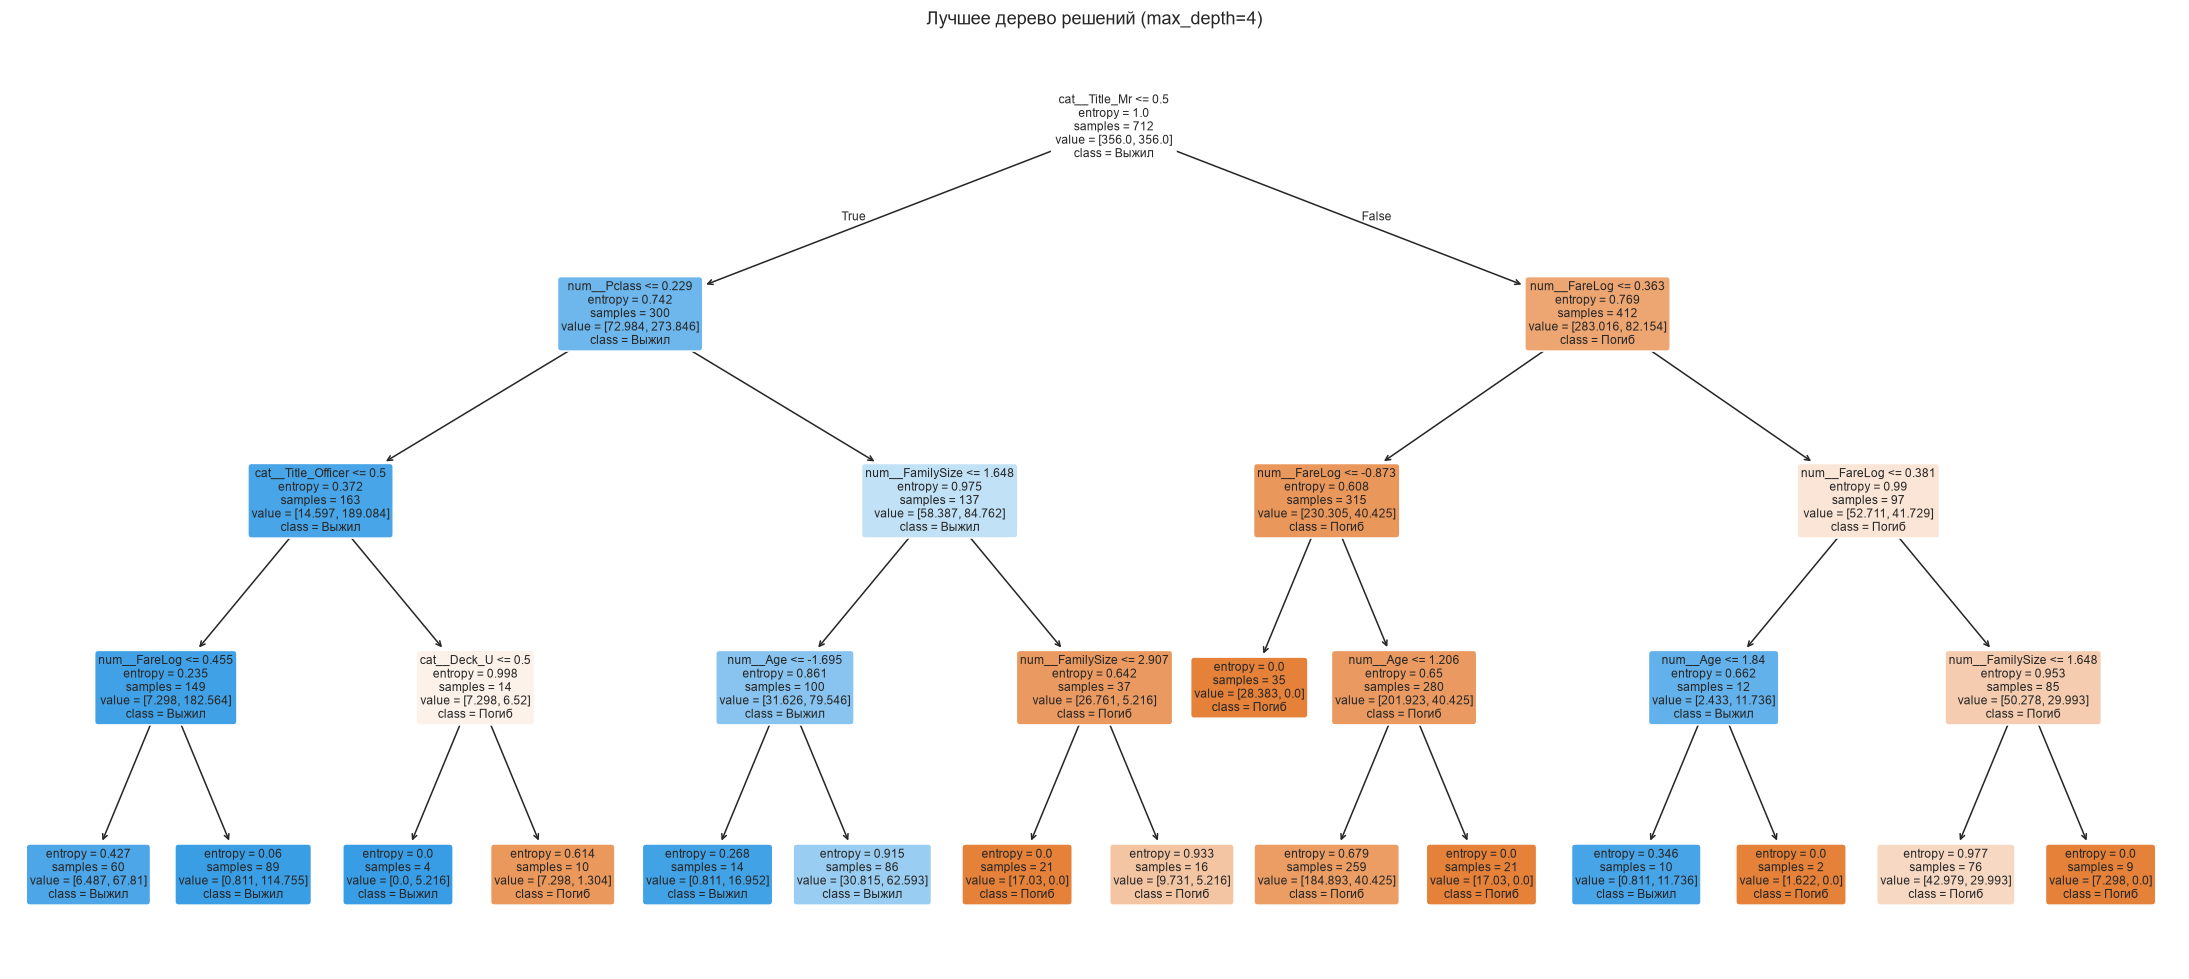

In [34]:
# Интерпретируемость: визуализация лучшего дерева решений
best_tree_pipe = tuned_models["DecisionTree"]
best_tree_model = best_tree_pipe.named_steps["clf"]
feature_names = best_tree_pipe.named_steps["prep"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(best_tree_model, feature_names=feature_names, class_names=["Погиб", "Выжил"],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Лучшее дерево решений (max_depth={best_tree_model.get_depth()})")
fig.tight_layout()
fig.savefig(FIG_DIR / "14_best_tree.png", bbox_inches="tight")
plt.show()

## 8. Заключение

В работе решена задача бинарной классификации выживаемости пассажиров «Титаника» (891 наблюдение, 12 исходных столбцов, целевая переменная `Survived`).

**Что сделано:**

1. Проведён разведочный анализ: выявлены сильнейшие предикторы — пол, класс билета, возраст и наличие каюты; обработаны пропуски (`Age`, `Cabin`, `Embarked`).
2. Выполнено конструирование признаков: `Title`, `FamilySize`, `IsAlone`, `Deck`, `HasCabin`, `FareLog`, `AgeKnown`. Все преобразования оформлены в `ColumnTransformer`/`Pipeline`, что исключает утечку данных при кросс-валидации.
3. Данные стратифицированно разделены на train (80 %) и test (20 %).
4. Построены 8 классификаторов пяти групп методов: четыре варианта Naive Bayes, дерево решений, LDA, SVM и kNN. Рассчитаны Accuracy, Precision, Recall, F1, AUC-ROC; построены ROC-кривые, столбчатые диаграммы и матрицы ошибок.
5. Для каждого метода выполнен подбор гиперпараметров (`GridSearchCV`, 5-fold StratifiedKFold, критерий F1). Построены зависимости качества от `max_depth`, `k`, `alpha`, `shrinkage`, а также heatmap по `C`/`gamma` для SVM.
6. Реализована нейронная сеть на TensorFlow/Keras (32 → 16 → 1, ReLU, Dropout, Adam, binary crossentropy, class_weight, EarlyStopping). Проведено 12 дополнительных экспериментов с архитектурой, активацией, learning rate, оптимизатором, размером батча, dropout и числом эпох.
7. Обучение всех сетей залогировано в TensorBoard (`logs_tb_titanic/`): scalars, histograms, graph.
8. Построена сводная таблица сравнения всех подходов.

**Основные выводы:**

- Классические модели на Titanic показывают Accuracy **0.737–0.849** и AUC-ROC **0.774–0.862**. Лучший результат по Accuracy, F1 и AUC — у **LDA**: 0.849 / 0.797 / 0.862.
- Подбор гиперпараметров дал заметный прирост только там, где стартовая конфигурация была далека от оптимума: дерево решений **+0.107 F1** (0.672 → 0.779) и kNN **+0.033 F1** (0.731 → 0.764). Для LDA и SVM выигрыш на тесте отсутствовал — их базовые настройки уже были близки к оптимальным.
- Наивный Байес быстр и интерпретируем, но уступает по F1 (0.685–0.747). GaussianNB обеспечивает максимальный Recall (0.855) ценой низкой Precision (0.648) и худшего AUC (0.774). BernoulliNB с бинаризацией даёт лучший AUC среди NB (0.833).
- Нейросеть: baseline (32 → 16, Adam, Dropout 0.2) — F1 0.723, AUC 0.851. Лучший F1 среди сетей — **0.767** (`lr = 1e-2`), лучший AUC — **0.866** (`batch = 128`). Даже после настройки сеть не превосходит LDA по F1: сказывается малый объём данных (712 обучающих объектов).
- Для практического применения оптимален баланс **интерпретируемости и качества** — **LDA** (линейные коэффициенты, устойчивость, высокий F1/AUC). Если критичен Recall — GaussianNB или дерево с `class_weight='balanced'`; если нужна наглядная логика решений — неглубокое дерево (`max_depth = 4`). Нейросеть имеет смысл при расширении датасета.
- TensorBoard подтверждает: EarlyStopping остановил baseline на 28-й эпохе, Dropout и регуляризация сдерживают переобучение, а learning rate критически влияет на скорость сходимости (при `lr = 1e-4` сеть не успевает обучиться за 80 эпох).

**Ограничения:** объём данных (891 объект) невелик, поэтому разница в несколько тысячных метрик может быть статистическим шумом; для надёжного выбора модели желательна повторная кросс-валидация и/или расширение датасета.

## Приложение. Как запустить

1. Установить зависимости:

```bash
pip install numpy pandas scikit-learn matplotlib seaborn tensorflow tensorboard jupyter
```

2. Запустить Jupyter:

```bash
jupyter notebook LR2_classification_nn.ipynb
```

3. Выполнить все ячейки (**Run All**). Файл `titanic.csv` уже лежит в каталоге; при его отсутствии данные скачаются автоматически.

4. Посмотреть логи обучения:

```bash
tensorboard --logdir logs_tb_titanic --port 6006
```

и открыть http://localhost:6006.

Все рисунки сохраняются в `figures_titanic/`, логи TensorBoard — в `logs_tb_titanic/`.